<a href="https://colab.research.google.com/github/Murcha1990/GenModels_AI26/blob/main/Homeworks/Base/GenDL_HT4_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнее задание 4 (base): авторегрессионные модели и мультимодальность

В этом домашнем задании вам предлагается обучить авторегрессионную модель для генерации изображений (PixelCNN), а также сделать подход мультимодальным,  обусловив модель на CLIP-эмбеддинги.

# Рекомендации (sanity check) по обучению модели

1) Обучите вашу модель на выборке из 100 картинок (первые 100 из датасета) + всех возможных кепшенов для них. Модель должна переобучится под эти 100 картинки и выдавать очень низкий bpd и генерить хорошие картинки. Это санити чек для задачи 4 и 5. Оставьте этот ран в ноутбуке, чтобы мы тоже видели (постарайтесь сделать это красиво, не копипастя все клетки ноутбука, а именно конфигурируя эксперимент)

2) Идем на весь датасет, чтобы научиться обобщаться на разные картинки и промпты. Хорошая в рамках дз модель должна научиться как минимум рисовать background-ы и иногда показывать очертания птиц. Чтобы птицы (или что-то на них похожее) стали более видны (и cond и uncond), используйте температуру при сэмплировании (подумайте почему это влияет). Будет заметно влиятнее промпта

В задаче можно точно выбить bpd в 8.9 — как ориентир после долгого обучения. 9.8 должно выбиваться довольно быстро.

**При обучении замеряйте и выводите качество модели - по метрике bpd.**

### Задание 1 (0 баллов)

Скачайте [датасет про птиц с HuggingFace](https://huggingface.co/datasets/weiywang/CUB_200_2011_CAP).

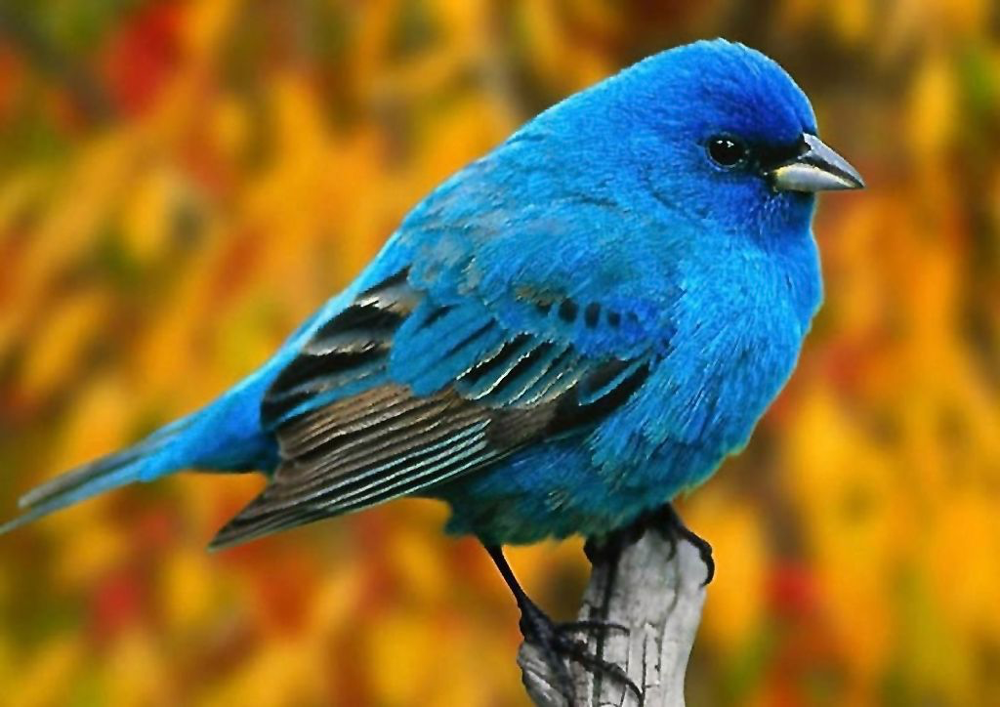

In [1]:
# ваш код здесь
from datasets import load_dataset
import numpy as np

cub_data = load_dataset("weiywang/CUB_200_2011_CAP", split="train")
labels = np.array(list(cub_data["label"]))

print(cub_data)
print("Всего видов птиц (классов):", len(set(labels)))
print(cub_data[0]["label"])
print(repr(cub_data[0]["text"]))

Dataset({
    features: ['image', 'text', 'label'],
    num_rows: 11787
})
Всего видов птиц (классов): 200
Acadian Flycatcher
'a bird with big eyes and brown tones all over. white underbelly and pointed beaka very small bird whose entire coat is covered with varying shades of green.this bird is brown with white on its chest and has a very short beak.this small bird has grey wingbars with a white belly.this light brown and yellow bird features large black eyes and a small beak.small grey green and brown bird with medium black tarsus and medium beakthis bird has wings that are green and black and has a white bodythis bird has wings that are black and white and has a green headthis bird has wings that are grey and has a white bellythis bird is brown and white in color, and has a brown beak.'


В столбце `text` для каждой картинки склеено в один текст примерно 10 описаний разных людей. Иногда между ними есть точка, а иногда подписи склеены прямо без разделителя. Поэтому сначала порежу текст по точкам, а потом дополнительно те места, где после буквы сразу начинается типичное начало новой подписи (`this`, `the bird`, `a small` ну и т.д.). Сделал это в задании 2.

### UPD: VQ-VAE

VQ-VAE - это автоэнкодер, который позволяет сжимать большие входные изображения в дискретное латентное пространство (последовательность кодов) и декодировать их обратно (см. рис).

<img src="https://substackcdn.com/image/fetch/$s_!dRiM!,f_auto,q_auto:good,fl_progressive:steep/https%3A%2F%2Fsubstack-post-media.s3.amazonaws.com%2Fpublic%2Fimages%2F81630fcc-b23e-4f06-831f-690aff70e03b_1215x476.png" width="800" height="400">

VQ-VAE состоит из трех частей. Энкодер кодирует входное изображение $x \in \mathbb{R}^{B \times C \times H \times W}$ в непрерывное латентное пространство $z_e \in \mathbb{R}^{B \times D \times H_{h} \times W_{h}}$. Quantizer смотрит на каждый вектор из $z_e$ ($H_{h} \times W_{h}$ штук длины $D$) и заменяет их на ближайший похожий вектор из словаря-векторов (codebook), который обучался вместе с моделью. Сам $z_e$после такой операции заменяется на $z_q$ (те же размеры, но каждый вектор заменен на ближайшего из кодбука). $z_q$ можно хранить либо как непрерывный тензор $\mathbb{R}^{B \times D \times H_{h} \times W_{h}}$, либо просто хранить $B \times  H_{h} \times W_{h}$ дискретных индексов из кодбука, где индексы соответствуют номеру вектора в кодбуке (для примера, если у нас 4096 векторов в кодбуке и мы $z_e$ заменили на вектора на местах $1, 2000, 2, 10$ из кодбука, то теперь $z_q$ в дискретном виде это просто массив $1, 200, 2, 10$). Декодер, последняя часть VQ-VAE, берет $z_q$ и переводит из кодов обратно в вектора из кодбука (если $z_q$ был в виде кодов, а не векторов) и прогоняет $z_q$ через набор слоев, чтобы получить изображение $\hat{x} \simeq x$.


$H_{h} \times W_{h}$ как правило сильно меньше оригинальных $H \times W$, поэтому многие генеративные модели используют VQ-VAE для генерации высококачественных изображений без значительного усложнения вычислительной сложности. Действительно, если вместо авторегрессионной генерации $С \times H \times W$, где $H, W \ge 128$ мы будем работать с дискретным тензором $H_{h} \times W_{h}$, где $H_h, W_h \le 32$, то мы сможем генерировать качественные изображения с той же вычислительной сложностью как если бы сделали resize изначальных картинок в $32\times32$, но при этом не теряем в качестве изображений (ведь финальное изображение получается прогоном кодов через декодер).

Давайте посмотрим как это работает:

In [2]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

In [3]:
# Скачаем предобученную VQ-VAE

from diffusers import VQModel
vqvae = VQModel.from_pretrained("microsoft/vq-diffusion-ithq", subfolder="vqvae")
vqvae.to(device)

An error occurred while trying to fetch microsoft/vq-diffusion-ithq: microsoft/vq-diffusion-ithq does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


VQModel(
  (encoder): Encoder(
    (conv_in): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (down_blocks): ModuleList(
      (0): DownEncoderBlock2D(
        (resnets): ModuleList(
          (0-1): 2 x ResnetBlock2D(
            (norm1): GroupNorm(32, 64, eps=1e-06, affine=True)
            (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (norm2): GroupNorm(32, 64, eps=1e-06, affine=True)
            (dropout): Dropout(p=0.0, inplace=False)
            (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (nonlinearity): SiLU()
          )
        )
        (downsamplers): ModuleList(
          (0): Downsample2D(
            (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2))
          )
        )
      )
      (1): DownEncoderBlock2D(
        (resnets): ModuleList(
          (0): ResnetBlock2D(
            (norm1): GroupNorm(32, 64, eps=1e-06, affine=True)
            (conv1): Conv2d(64

Скачаем картинку для примера

In [4]:
!wget "https://upload.wikimedia.org/wikipedia/commons/1/16/Myophonus_caeruleus_-_Ang_Khang_edit1.jpg" -O example.jpg

--2026-11-22 14:36:23--  https://upload.wikimedia.org/wikipedia/commons/1/16/Myophonus_caeruleus_-_Ang_Khang_edit1.jpg
Resolving upload.wikimedia.org (upload.wikimedia.org)... 185.15.59.240, 2a02:ec80:300:ed1a::2:b
Connecting to upload.wikimedia.org (upload.wikimedia.org)|185.15.59.240|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1474949 (1.4M) [image/jpeg]
Saving to: ‘example.jpg’

example.jpg         100%[===================>]   1.41M  2.34MB/s    in 0.6s    

2026-11-22 14:36:24 (2.34 MB/s) - ‘example.jpg’ saved [1474949/1474949]



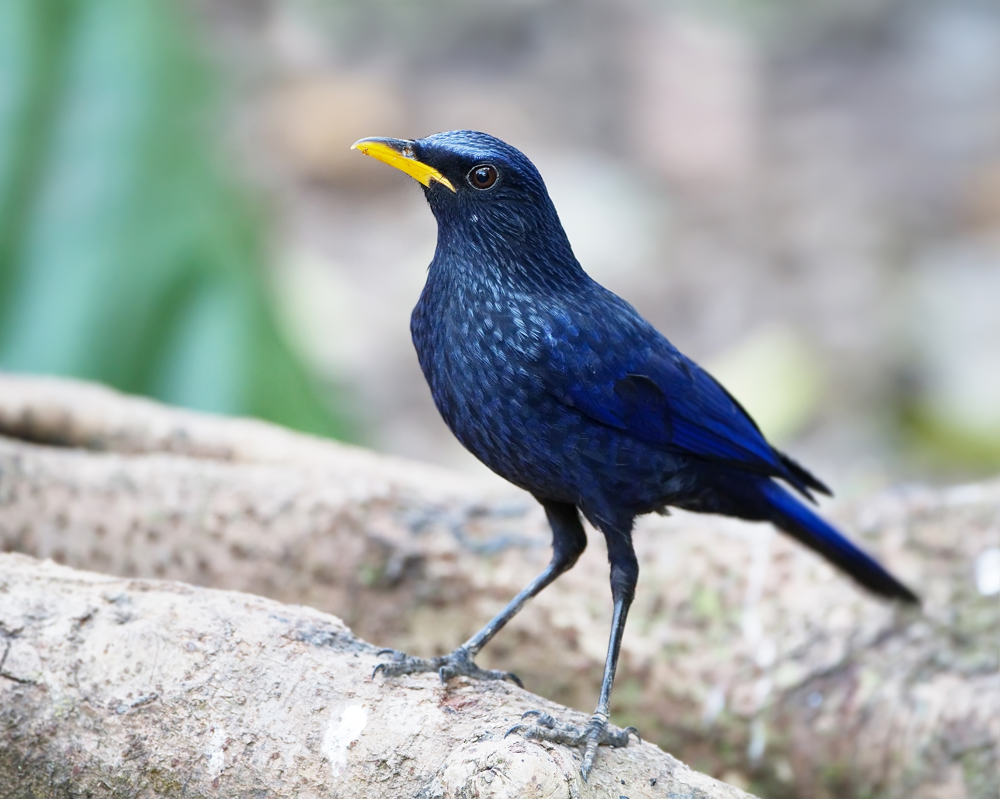

In [ ]:
from PIL import Image

img = Image.open("example.jpg")
img

VQ-VAE этот работает на изображениях $256\times 256$, поэтому ресайзим

In [8]:
from torchvision import transforms

x = transforms.Resize((256, 256))(img)
x = transforms.ToTensor()(x)
x.shape

Код для получения кодов и декодирования изображения:

In [6]:
def img_to_codes(x, vqvae):
    if x.ndim != 4:
        x = x.unsqueeze(0)
    # для нормализации вход не [0, 1], а [-1, 1]
    x = x * 2 - 1
    # применяем энкодер
    latent = vqvae.encode(x).latents
    # получаем z_q и соответствующие коды
    quant, commit_loss, (_, _, indices) = vqvae.quantize(latent)
    # коды тут flatten, решейпим обратно
    B, _, Hc, Wc = latent.shape
    if indices.dim() == 1:
        codes = indices.view(B, Hc, Wc)
    else:
        codes = indices
    return codes

def codes_to_img(codes, vqvae):
    B, Hc, Wc = codes.shape
    codes = codes.view(-1)
    # получаем непрерывное z_q из соответствующих кодов,
    # смотря на вектора из кодбука по индексам
    quant = vqvae.quantize.get_codebook_entry(
        codes,
        shape=(B, Hc, Wc, vqvae.quantize.vq_embed_dim)  # (B, H, W, C)
    )
    # декодируем
    quant2 = vqvae.post_quant_conv(quant)
    dec = vqvae.decoder(quant2, quant if vqvae.config.norm_type == "spatial" else None)
    return (dec + 1) / 2

Применим:

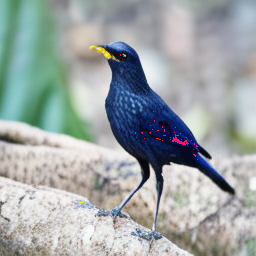

In [ ]:
codes = img_to_codes(x.to(device), vqvae)
hat_x = codes_to_img(codes, vqvae)
transforms.ToPILImage()(hat_x[0])

In [ ]:
codes

tensor([[[ 817, 2035, 1131,  ..., 2121, 3251,  308],
         [ 959, 3175, 3348,  ...,  798,  890,  626],
         [4008,  485, 1446,  ...,  300, 2945,  113],
         ...,
         [1287, 3999, 2154,  ..., 1070, 2207, 1166],
         [3132, 4010,  896,  ...,  729, 2359, 3617],
         [1282, 1434, 3435,  ...,  312,  109, 1547]]], device='cuda:0')

Видим, что у нас получилось довольно хорошо восстановить изображения из кодов. Но какие размеры у `codes`?

In [ ]:
codes.shape

torch.Size([1, 32, 32])

$B=1$, т.е. вместо $3\times 256\times 256$ (RGB) мы получаем всего лишь $32\times 32$.

Раньше, дискретных значений было в одном пикселе было $3 \cdot 256$ (цвета в RGB по каждому каналу). Теперь кол-во дискретных значения задается количеством кодов в кодбуке vqvae $N_q$

In [ ]:
vqvae.config.num_vq_embeddings

4096

Как и прежде, мы можем генерировать подобные дискретные тензоры авторегрессионно с помощью PixelCNN, но если раньше мы работали в пространстве изображений, то теперь будем работать в латентном. Как и раньше, мы будем считать, что $32\times32$ тензор это последовательность токенов со значениями из $[0, N_q-1]$, которую мы считываем построчно слево направо. Наш PixelCNN, как и раньше, будет смотреть только на предыдущие токены, чтобы генерировать новый. Модель каждый шаг будет предсказывать вероятностное распределение на словаре: $[0, N_q-1]$

То есть, все буквально, как и раньше, но вместо RGB изображений, мы будем генерировать `codes`. Чтобы получить RGB, мы просто прокинем codes через декодер VQ-VAE и получим RGB изображений в высоком разрешении.

P.S. Поскольку VQ-VAE сильно сжимает изображение, мы заодно избавляемся от высокочастотного шума, который присутствует в цветных натуральных изображениях и мешает авторегрессионным генераторам делать хорошую генерацию. RGB шум из-за слишком разнообразного фона на картинках птиц. VQ-VAE, за счет сжатия, делает каждый токен очень значимым (нет двух соседних токенов, которые по сути отвечают лишь за две соседние маленькие точки фона, мешая PixelCNN обучиться). Действительно, если изначально картинка была с стороной 256, а стала с 32 в  `codes`, то каждый токен отвечает за участок размера $8\times8$, что куда более значимо, чем один пиксель в исходном изображении. Можно было бы сказать, что такого же эффекта "значимости" можно было бы добиться просто resize в $32\times 32$ RGB картинки, но PixelCNN путался бы из-за цветов (3 канала в RGB, в `codes` нет каналов), а также сами пиксели имели бы лишь поверхностное значение. В VQ-VAE токены смоделированы специально для сжатия и восстановления обратно в $256\times 256$, поэтому каждый токен содержит в себе более глубокую и детальную информацию, чем просто resize-нутый пиксель.

### Задание 2 (1 балл).

Скачайте любую версию предобученного CLIP на ваш вкус, примените текстовый кодировщик к описаниям птиц из датасета (столбец "text") и сохраните получившиеся эмбеддинги.

Возьмите из датасета две картинки с визуально похожими птицами и посчитайте косинусную близость эмбеддингов подписей к этим фото, оцените корректность результата.

In [5]:
# ваш код здесь
from transformers import CLIPModel, CLIPTokenizer
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from dataclasses import dataclass
import math

RAND_ST = 777
random.seed(RAND_ST)
np.random.seed(RAND_ST)
torch.manual_seed(RAND_ST)
torch.cuda.manual_seed_all(RAND_ST)


clip_name_model = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(clip_name_model).to(device).eval()
clip_tokenizer = CLIPTokenizer.from_pretrained(clip_name_model)
# размер итогового эмбеддинга 512
clip_dim = clip_model.config.projection_dim  

print("Рзмерность проекции:", clip_dim)


@torch.no_grad()
def encode_texts(texts, batch_size=512):
    
    embs = []
    
    for i in range(0, len(texts), batch_size):
        token = clip_tokenizer(
            texts[i:i + batch_size], 
            padding=True, 
            truncation=True,
            max_length=77,       # у модели CLIP максимум 77 токенов
            return_tensors="pt"
        ).to(device)
        
        out = clip_model.text_model(input_ids=token.input_ids, attention_mask=token.attention_mask)
        embs.append(clip_model.text_projection(out.pooler_output).float().cpu())
        
    return torch.cat(embs)

Рзмерность проекции: 512


In [9]:
# из-за проблем в тексте подписей к картинкам, о которых пояснил в задании 1, написал обработчик для правильной их склейки
import re

regul_exp = re.compile(r"(?<=[a-z])(?=(?:this|small bird|a small|a very|a tiny|the bird)\b)")


def split_captions(text):
    caps = []
    for chunk in text.split("."):
        for cap in regul_exp.split(chunk):
            cap = cap.strip(" ,;")
            # убираем короткие (возможно мусорные) получившиеся описания + дно-два слова: bird, small, the bird
            if len(cap.split()) >= 3:
                caps.append(cap)
    return caps

# проверка на адекватность нарезки
for cap in split_captions(cub_data[0]["text"]):
    print("-", cap)

- a bird with big eyes and brown tones all over
- white underbelly and pointed beak
- a very small bird whose entire coat is covered with varying shades of green
- this bird is brown with white on its chest and has a very short beak
- this small bird has grey wingbars with a white belly
- this light brown and yellow bird features large black eyes and a small beak
- small grey green and brown bird with medium black tarsus and medium beak
- this bird has wings that are green and black and has a white body
- this bird has wings that are black and white and has a green head
- this bird has wings that are grey and has a white belly
- this bird is brown and white in color, and has a brown beak


In [10]:
import os
from tqdm.auto import tqdm

SAVE_DIR = "artifacts"
os.makedirs(SAVE_DIR, exist_ok=True)

In [11]:
# разбиваем тексты на отдельные подписи и храним их в списке
# подписи картинки i лежат в captions[cap_ptr[i] : cap_ptr[i + 1]]
# такой формат (как в разреженных матрицах CSR) удобен, когда у объектов разное число элементов
captions, cap_ptr = [], [0]

# 
for text in tqdm(cub_data["text"], desc="нарезка описаний"):
    caps = split_captions(text) or [text[:300]]
    captions.extend(caps)
    cap_ptr.append(len(captions))
    
cap_ptr = torch.tensor(cap_ptr)

# разности соседних элементов, то есть число подписей у каждой картинки
n_caps = cap_ptr.diff()
print(f"Всего подписей: {len(captions)}; на одну картинку: "
      f"min={n_caps.min().item()}, \
      max={n_caps.max().item()}, \
      mean={n_caps.float().mean():.1f}")

# поучаем эмбединги описаний
cap_emb = encode_texts(captions)        # (число подписей, 512)
empty_emb = encode_texts([""])[0]       # эмбеддинг пустого промпта, понадобится для CFG

print("cap_emb:", tuple(cap_emb.shape))

torch.save({"captions": captions, "cap_ptr": cap_ptr, "cap_emb": cap_emb.half(), "empty_emb": empty_emb},
           f"{SAVE_DIR}/clip_text_emb.pt")

нарезка описаний:   0%|          | 0/11787 [00:00<?, ?it/s]

Всего подписей: 115222; на одну картинку: min=6,       max=20,       mean=9.8
cap_emb: (115222, 512)


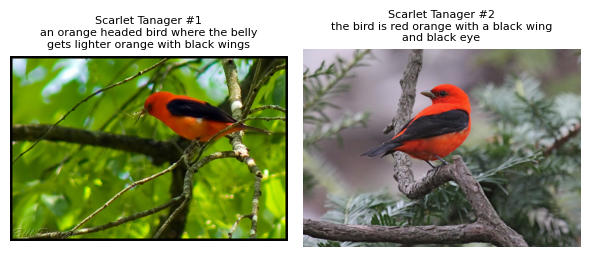

In [14]:
import matplotlib.pyplot as plt
import textwrap


def image_text_emb(i):
    """Средний нормированный эмбеддинг всех подписей картинки i."""
    e = F.normalize(cap_emb[cap_ptr[i]:cap_ptr[i + 1]], dim=-1)
    # усреднением убираем шум отдельных подписей
    return F.normalize(e.mean(0), dim=-1)


def mean_pairwise_cos(i, j):
    """Средняя косинусная близость по всем парам (подпись картинки i, подпись картинки j)."""
    emb_i = F.normalize(cap_emb[cap_ptr[i]:cap_ptr[i + 1]], dim=-1)
    emb_j = F.normalize(cap_emb[cap_ptr[j]:cap_ptr[j + 1]], dim=-1)
    # усредняем по всем парам
    return (emb_i @ emb_j.T).mean().item()


def idx_of(label, k=0):
    """Возращает индекс картинки с нужным label
    k выбирает, какую по счёту картинку этого вида взять
    по дефолту берем первую
    """
    return int(np.where(labels == label)[0][k])


# две картинки одного вида (алая танагра: красная с чёрными крыльями, визуально похожи) 
chosen = {
    "Scarlet Tanager #1": idx_of("Scarlet Tanager", 0),
    "Scarlet Tanager #2": idx_of("Scarlet Tanager", 7)
}

names, ids = list(chosen), list(chosen.values())

fig, axes = plt.subplots(1, len(ids), figsize=(3 * len(ids), 4.5))
for ax, name, i in zip(axes, names, ids):
    ax.imshow(cub_data[i]["image"].convert("RGB"))
    ax.set_title(f"{name}\n" + textwrap.fill(captions[cap_ptr[i]], 40), fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [15]:
i, j = ids[0], ids[1]
cos = (image_text_emb(i) @ image_text_emb(j)).item()
print(f"Косинусная близость подписей двух Scarlet Tanager: {cos:.3f}")

Косинусная близость подписей двух Scarlet Tanager: 0.985


**Выводы:** 

- Взяты две картинки Scarlet Tanager: обе ярко-красные с чёрными крыльями, визуально это один и тот же тип птицы. Косинусная близость эмбеддингов их подписей равна **0.985**.
- Такое значение выглядит высоким. Часть близости, скорее всего, даёт общий шаблон подписей («this bird has …»), а не только цвет и форма конкретной птицы: почти все тексты датасета устроены одинаково. По одному числу это не проверить, для проверки нужна была бы близость случайных пар птиц например;
- Сам результат правдоподобный: подписи описывают одну и ту же внешность, и CLIP ставит им близкие векторы. Эти эмбеддинги можно использовать как условие для генерации.

### Задание 3 (0.5 балла).

Соберите картинки и получившиеся эмбеддинги в датасеты. Сохраните два датасета: один только с изображениями, другой - с изображениями и эмбеддингами подписей.

- Сконвертируйте картинки в соответствующие `codes` (используйте функции выше)

Hint: внимательно посмотрите на кол-во каналов в изображениях датасета и размеры картинок, предобработайте картинки перед подачей в VQ-VAE

Hint 2: сначала используется сабсет из вашего датасета для дебага, потому что датасет конвертируется долго, после дебага используйте весь

In [16]:
# ваш код здесь
from collections import Counter

# смотрим какие картинки лежат в датасете. число каналов и размеры
# берём 500 случайных картинок и считаем, сколько из них в каком режиме (RGB — 3 канала, L — 1 канал)
check_idx = random.sample(range(len(cub_data)), 500)
modes = Counter(cub_data[i]["image"].mode for i in check_idx)
sizes = np.array([cub_data[i]["image"].size for i in check_idx])
print("Режимы картинок:", dict(modes))
print("Ширина: от", sizes[:, 0].min(), "до", sizes[:, 0].max(), "| высота: от", sizes[:, 1].min(), "до", sizes[:, 1].max())

Режимы картинок: {'RGB': 500}
Ширина: от 230 до 500 | высота: от 146 до 500


Картинки разного размера (ширина/высота от 160 до 500), а часть из них чёрно-белая (режим `L`, один канал). VQ-VAE ждёт RGB 256×256, поэтому нужно:
1. перевести всё в RGB (`convert("RGB")` копирует единственный канал в три);
2. ресайз меньшей стороны до 256 и вырезать центральный квадрат 256×256 (птицы почти всегда в центре кадра, а пропорции не искажаются);
3. `ToTensor` даёт значения в [0, 1], а перевод в [-1, 1] уже делает функция `img_to_codes`.

Сразу же кодируем и горизонтально отражённую картинку: это аугментация, которая пригодится в задании 8.

In [17]:
IMG_SIZE = 256
N_TOKENS = vqvae.config.num_vq_embeddings  # 4096 — размер словаря кодов
CODE_SIZE = 32                             # коды имеют размер 32x32

img_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
])


class TensorImages(Dataset):
    """Картинки из HF-датасета в тензоры (3, 256, 256) в [0, 1]"""

    def __init__(self, hf_ds, indices, transform=img_transform):
        self.hf_ds, self.indices, self.transform = hf_ds, list(indices), transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        # здесьже применим все необходимые трансформации - на выходе уже тензор
        img = self.hf_ds[int(self.indices[i])]["image"].convert("RGB")
        return self.transform(img)


@torch.no_grad()
def encode_images(hf_ds, indices, batch_size=16, num_workers=2):
    """Возвращает коды картинок и их горизонтальные отражения. На выходе будет два тензора (N, 32, 32) в int16 (для экономии памяти)"""
    
    vqvae.eval()
    loader = DataLoader(TensorImages(hf_ds, indices), batch_size=batch_size, num_workers=num_workers)
    codes, codes_flip = [], []
    
    for x in tqdm(loader, desc="VQ-VAE encode"):
        x = x.to(device)
        codes.append(img_to_codes(x, vqvae).cpu().to(torch.int16))
        codes_flip.append(img_to_codes(x.flip(-1), vqvae).cpu().to(torch.int16))
        
    return torch.cat(codes), torch.cat(codes_flip)


@torch.no_grad()
def decode_codes(codes, batch_size=16):
    """Коды (N, 32, 32) в картинки (N, 3, 256, 256) в [0, 1] на CPU"""
    
    imgs = []
    
    for k in range(0, len(codes), batch_size):
        batch = codes[k:k + batch_size].long().to(device)                   # индексы для кодбука должны быть int64
        imgs.append(codes_to_img(batch, vqvae).clamp(0, 1).float().cpu())  # .clamp(0,1) обрезает значения декодера, вылезшие чуть за диапазон
    
    return torch.cat(imgs)


def show_images(imgs, titles=None, ncols=5, size=3.0, suptitle=None):
    
    n = len(imgs)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows * 1.15), squeeze=False)
    
    for ax in axes.flat:
        ax.axis("off")
        
    for k in range(n):
        ax = axes.flat[k]
        ax.imshow(imgs[k].permute(1, 2, 0).numpy())     # в PyTorch порядок (C,H,W), а matplotlib ждёт (H,W,C)
        if titles is not None:
            ax.set_title(textwrap.fill(titles[k], 32), fontsize=8)
            
    if suptitle:
        fig.suptitle(suptitle)
        
    plt.tight_layout()
    plt.show()


def show_codes(codes, titles=None, **kwargs):
    """Отрисовка сгенерированных кодов: здесь же коды переводятся в картинки декодером VQ-VAE"""
    show_images(decode_codes(codes), titles, **kwargs)

VQ-VAE encode:   0%|          | 0/4 [00:00<?, ?it/s]

torch.Size([64, 32, 32]) torch.int16 min = 0 max = 4095


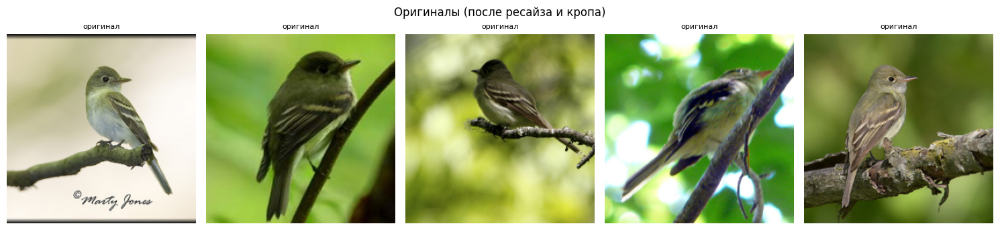

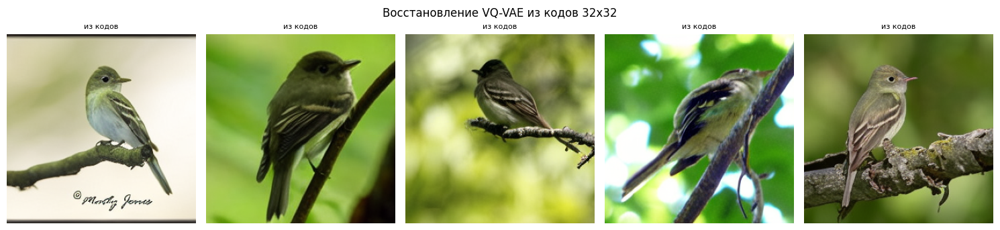

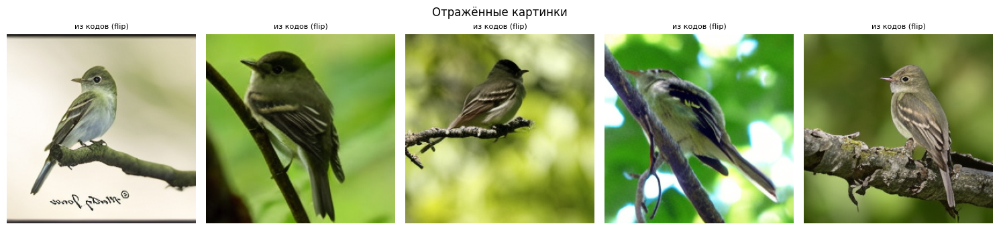

In [18]:
# отладка на маленьком сабсете согласно hint
# проверяем форму, диапазон кодов и качество восстановления

DEBUG_N = 64
# сначала кодируем маленький кусок и проверяем форму (64, 32, 32), тип и что коды лежат в [0,4095]
dbg_codes, dbg_codes_flip = encode_images(cub_data, range(DEBUG_N))
print(dbg_codes.shape, dbg_codes.dtype, "min =", dbg_codes.min().item(), "max =", dbg_codes.max().item())

# сравним визуально
orig = torch.stack([TensorImages(cub_data, range(5))[k] for k in range(5)])
show_images(orig, ["оригинал"] * 5, suptitle="Оригиналы (после ресайза и кропа)")
show_codes(dbg_codes[:5], ["из кодов"] * 5, suptitle="Восстановление VQ-VAE из кодов 32x32")
show_codes(dbg_codes_flip[:5], ["из кодов (flip)"] * 5, suptitle="Отражённые картинки")

In [19]:
codes_path = f"{SAVE_DIR}/birds_codes.pt"            # датасет 1: только изображения (коды)
text_path = f"{SAVE_DIR}/birds_codes_text.pt"        # датасет 2: изображения + эмбеддинги подписей

if os.path.exists(codes_path):
    data_img = torch.load(codes_path, weights_only=False)
    codes_all, codes_flip_all = data_img["codes"], data_img["codes_flip"]
else:
    codes_all, codes_flip_all = encode_images(cub_data, range(len(cub_data)))  

data_img = {"codes": codes_all, "codes_flip": codes_flip_all, "labels": list(labels)}
data_txt = {**data_img, "captions": captions, "cap_ptr": cap_ptr,
            "cap_emb": cap_emb.half(), "empty_emb": empty_emb}
torch.save(data_img, codes_path)
torch.save(data_txt, text_path)
print("codes:", tuple(codes_all.shape), "| cap_emb:", tuple(cap_emb.shape))

codes: (11787, 32, 32) | cap_emb: (115222, 512)


**Выводы:** успешно сохарнено 2 датасета согласно задания.

### Задание 4 (2 балла).

- Обучите [модель (PixelCNN)](https://colab.research.google.com/drive/1EIsBxlTcz3ZB0j-ZxN1gWD2dSQq6krPj?usp=sharing) только на `codes` птиц. Модифицируйте размерности тензоров в модели, где это необходимо - чтобы она корректно работала с данными изображениями (обратите внимание на то, какие дискретные числа должны предсказывать ваша модель)

- Сделайте обучаемый `nn.Embedding` для `codes` перед подачей в слои свертки

- Вы можете менять гиперпараметры для улучшения качества генерации

- Выведите на экран 10 сгенерированных картинок, оцените результат, напишите выводы

Hint: добавьте конвертацию кодов в изображения в функцию отрисовки картинок, а не в `sample`.

In [20]:
# ваш код здесь
class CodesDataset(Dataset):
    """Только коды картинок — для безусловной модели"""

    def __init__(self, data, indices, flip_p=0.0):
        self.codes, self.codes_flip = data["codes"], data["codes_flip"]
        self.indices = list(indices)
        # вероятность отражения
        self.flip_p = flip_p

    def __len__(self):
        return len(self.indices)

    def get_codes(self, i):
        codes = self.codes_flip if random.random() < self.flip_p else self.codes
        return codes[i].long()

    def __getitem__(self, i):
        return self.get_codes(self.indices[i])


class CodesTextDataset(CodesDataset):
    """Коды картинки + CLIP-эмбеддинг одной из её подписей"""

    def __init__(self, data, indices, flip_p=0.0, random_caption=True):
        super().__init__(data, indices, flip_p)
        self.cap_emb, self.cap_ptr = data["cap_emb"], data["cap_ptr"]
        self.random_caption = random_caption

    def __getitem__(self, i):
        # возвращает пару (коды, эмбеддинг подписи)
        indx = self.indices[i]
        lo, hi = int(self.cap_ptr[indx]), int(self.cap_ptr[indx + 1])
        # на обучении подпись выбирается случайно из подписей картинки: за много эпох модель видит все подпси и меньше переобучается
        j = random.randrange(lo, hi) if self.random_caption else lo
        
        return self.get_codes(indx), self.cap_emb[j].float()


N = len(codes_all)
perm = torch.randperm(N, generator=torch.Generator().manual_seed(0)).tolist()
# для валидации возьмем 5%
n_val = int(0.05 * N)
val_idx, train_idx = sorted(perm[:n_val]), sorted(perm[n_val:])

# первые 100 картинок для sanity check
sanity_idx = list(range(100))  
print(f"train: {len(train_idx)}, val: {len(val_idx)}, sanity: {len(sanity_idx)}")

codes_example, emb_example = CodesTextDataset(data_txt, train_idx)[0]
print(codes_example.shape, codes_example.dtype, emb_example.shape)

train: 11198, val: 589, sanity: 100
torch.Size([32, 32]) torch.int64 torch.Size([512])


### Реализую Gated PixelCNN на кодах VQ-VAE

In [21]:
class MaskedConv2d(nn.Module):
    """Маскированная свертка"""

    def __init__(self, c_in, c_out, mask, dilation=1):
        super().__init__()
        
        m_h, m_w = mask.shape
        padding = (dilation * (m_h - 1) // 2, dilation * (m_w - 1) // 2)
        self.conv = nn.Conv2d(c_in, c_out, (m_h, m_w), padding=padding, dilation=dilation)
        self.register_buffer("mask", mask[None, None].float())

    def forward(self, x):
        return F.conv2d(
            x, 
            self.conv.weight * self.mask, 
            self.conv.bias,
            padding=self.conv.padding, 
            dilation=self.conv.dilation
        )


def vertical_mask(k, mask_center):
    """Вертикальная маска k x k: строки выше центра; центральная строка — только если mask_center=False"""
    m = torch.ones(k, k)
    m[k // 2 + 1:, :] = 0
    if mask_center:
        m[k // 2, :] = 0
        
    return m


def horizontal_mask(k, mask_center):
    """Горизонтальная 1 x k: пиксели левее центра; сам центр — только если mask_center=False"""
    m = torch.ones(1, k)
    m[0, k // 2 + 1:] = 0
    if mask_center:
        m[0, k // 2] = 0
        
    return m


def gate(x):
    # делим каналы на 2
    a, b = x.chunk(2, dim=1)
    # здесь будет уже канал равный c
    return torch.tanh(a) * torch.sigmoid(b)


class GatedMaskedConv(nn.Module):
    
    def __init__(self, c, k=3, dilation=1, cond_dim=None, dropout=0.0):
        super().__init__()
        self.v_conv = MaskedConv2d(c, 2 * c, vertical_mask(k, False), dilation)
        self.h_conv = MaskedConv2d(c, 2 * c, horizontal_mask(k, False), dilation)
        # Обратной передачи (h в v) нет, иначе вертикальный стек увидел бы текущую строку
        self.v_to_h = nn.Conv2d(2 * c, 2 * c, 1)
        # Выходные 1 на 1 свёртки для остаточных связей
        self.v_out = nn.Conv2d(c, c, 1)
        self.h_out = nn.Conv2d(c, c, 1)
        # если модель условная то линейный слой переводит вектор условия в 4c чисел: 2c сдвигов для пре-активаций вертикального стека и 2c для горизонтального
        self.cond = nn.Linear(cond_dim, 4 * c) if cond_dim else None
        self.dropout = nn.Dropout(dropout)

    def forward(self, v, h, cond=None):
        v_feat = self.v_conv(v)
        h_feat = self.h_conv(h) + self.v_to_h(v_feat)
        # условие self.cond(cond) даёт (B, 4c), [:, :, None, None] превращает в (B, 4c, 1, 1), чтобы при сложении сдвиг растянулся на все позиции 32 на 32
        if self.cond is not None and cond is not None:
            cv, ch = self.cond(cond)[:, :, None, None].chunk(2, dim=1)
            v_feat = v_feat + cv
            h_feat = h_feat + ch
        v = v + self.v_out(self.dropout(gate(v_feat)))
        h = h + self.h_out(self.dropout(gate(h_feat)))
        return v, h


class PixelCNN(nn.Module):
    def __init__(self, n_tokens=4096, hidden=128, n_layers=12, kernel_size=3,
                 dilations=(1, 2, 4, 8), cond_dim=None, size=32, dropout=0.0):
        super().__init__()
        self.n_tokens, self.size, self.cond_dim = n_tokens, size, cond_dim
        self.tok_emb = nn.Embedding(n_tokens, hidden)
        # обучаемый позиционный эмбеддинг
        self.pos_emb = nn.Parameter(torch.zeros(1, hidden, size, size))
        # для первого слоя скрываем центр
        self.v_in = MaskedConv2d(hidden, hidden, vertical_mask(kernel_size, True))
        self.h_in = MaskedConv2d(hidden, hidden, horizontal_mask(kernel_size, True))

        # небольшой MLP для перевода 512 в hidden, адаптирует CLIP-вектор под модель, и его выход идёт во все слои
        if cond_dim:
            self.cond_net = nn.Sequential(nn.Linear(cond_dim, hidden), nn.SiLU(), nn.Linear(hidden, hidden))

        # создаем слои гейтов
        self.layers = nn.ModuleList([
            GatedMaskedConv(
                hidden, 
                kernel_size, 
                dilations[k % len(dilations)],
                hidden if cond_dim else None, 
                dropout
            )
            for k in range(n_layers)
        ])

        # голова - две свёртки 1 на 1 (то есть MLP, применённый к каждой позиции отдельно) с активацией ELU. на выходе 4096 логитов в каждой позиции
        self.head = nn.Sequential(nn.ELU(), nn.Conv2d(hidden, 2 * hidden, 1),
                                  nn.ELU(), nn.Conv2d(2 * hidden, n_tokens, 1))

    def features(self, x, cond=None):
        # основной проход по эмбеддингам x формы [B, hidden, H, W]
        H, W = x.shape[-2:]
        pos = self.pos_emb[:, :, :H, :W]
        # первые маскированные свертки плюс позиция
        v = self.v_in(x) + pos
        h = self.h_in(x) + pos
        # для условной модели
        c = self.cond_net(F.normalize(cond, dim=-1)) if (self.cond_dim and cond is not None) else None

        # прогон через все гейтид слои
        for layer in self.layers:
            v, h = layer(v, h, c)
        
        return h

    def forward(self, codes, cond=None, pos=None):
        """codes: (B, H, W) -> логиты (B, n_tokens, H, W); с pos=(i, j) -> логиты (B, n_tokens) только в этой позиции."""
        x = self.tok_emb(codes).permute(0, 3, 1, 2)
        h = self.features(x, cond)
        if pos is not None:
            i, j = pos
            return self.head(h[:, :, i:i + 1, j:j + 1]).flatten(1)
        return self.head(h)

# для вывода числа параметров в млн-х
def count_params(model):
    return sum(p.numel() for p in model.parameters()) / 1e6

In [22]:
LN2 = math.log(2)
USE_AMP = device == "cuda"
DEVICE_TYPE = "cuda" if device == "cuda" else "cpu"


@dataclass
class TrainConfig:
    name: str
    epochs: int = 30
    batch_size: int = 64
    lr: float = 1e-3
    weight_decay: float = 1e-4
    warmup_steps: int = 200
    grad_clip: float = 1.0
    p_uncond: float = 0.1      # доля примеров где промт заменяется пустым (CFG при обучении)
    flip_p: float = 0.0       # вероятность взять отражённую картинку - аугментация
    log_every: int = 1         # как часто печатать и считать val bpd
    resume: bool = True      # подгружать готовый чекпоинт, если он есть


def unpack(batch, conditional):
    """Для приведения к единому виду условной и безусловной модели
    Батч условного датасета — пара (коды, эмбеддинги), безусловного — только коды"""
    if conditional:
        codes, cond = batch
        return codes.to(device), cond.to(device)
    return batch.to(device), None


@torch.no_grad()
def evaluate_bpd(model, loader, conditional):
    
    model.eval()
    total, n = 0.0, 0
    
    for batch in loader:
        codes, cond = unpack(batch, conditional)
        with torch.autocast(device_type=DEVICE_TYPE, dtype=torch.float16, enabled=USE_AMP):
            logits = model(codes, cond)
        # F.cross_entropy принимает логиты [B, 4096, H, W] и правильные коды [B, H, W]
        total += F.cross_entropy(logits.float(), codes, reduction="sum").item()
        n += codes.numel()
        
    return total / n / LN2


def train_model(model, train_ds, val_ds, cfg, conditional=False, empty_emb=None):

    # если эксперимент уже обучен и файл существует то загружаем веса и историю, рисуем график и выходим
    ckpt_path = f"{SAVE_DIR}/{cfg.name}.pt"
    if cfg.resume and os.path.exists(ckpt_path):
        state = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(state["model"])
        history = state["history"]
        print(f"[{cfg.name}] загружен чекпоинт: train bpd {history['train_bpd'][-1]:.3f}"
              + (f", val bpd {history['val_bpd'][-1]:.3f}" if history["val_bpd"] else ""))
        plot_history(history, cfg.name)
        
        return history

    # трейн перемешивается каждую эпоху а val соотв-но нет
    train_loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=cfg.batch_size) if val_ds is not None else None

    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)

    # общее число шагов нужно для расписания lr
    total_steps = cfg.epochs * len(train_loader)

    # множитель к lr - линейно растёт от 0 до 1 за warmup_steps шагов, а косинус плавно ведёт от 1 к 0 к концу обучения
    def lr_lambda(step):
        warmup = min(1.0, (step + 1) / cfg.warmup_steps)
        cosine = 0.5 * (1 + math.cos(math.pi * min(step, total_steps) / total_steps))
        return warmup * cosine

    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    #empty — эмбеддинг пустого промпта на GPU
    empty = empty_emb.to(device).float() if empty_emb is not None else None

    history = {"epoch": [], "train_bpd": [], "val_epoch": [], "val_bpd": []}
    start = time.time()
    
    for epoch in range(1, cfg.epochs + 1):
        model.train()
        loss_sum, n_seen = 0.0, 0
        
        for batch in train_loader:
            codes, cond = unpack(batch, conditional)

            # CFG при обучении - для каждого примера бросаем монетку с вероятностью p_uncond = 0.1. где выпало, эмбеддинг подписи заменяется эмбеддингом пустой строки
            if conditional and cfg.p_uncond > 0:
                drop = torch.rand(codes.size(0), device=device) < cfg.p_uncond
                cond = torch.where(drop[:, None], empty.expand_as(cond), cond)

            with torch.autocast(device_type=DEVICE_TYPE, dtype=torch.float16, enabled=USE_AMP):
                logits = model(codes, cond)
            loss = F.cross_entropy(logits.float(), codes)

            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
            scaler.step(opt)
            scaler.update()
            sched.step()

            # копим сумму потерь чтобы получить средний трейн bpd за эпоху
            loss_sum += loss.item() * codes.size(0)
            n_seen += codes.size(0)

        # трейн bpd записываем каждую эпоху и раз в log_every эпох (и в последнюю) считаем val bpd и печатаем строку лога со временем
        history["epoch"].append(epoch)
        history["train_bpd"].append(loss_sum / n_seen / LN2)
        if epoch % cfg.log_every == 0 or epoch == cfg.epochs:
            msg = f"[{cfg.name}] epoch {epoch:3d}/{cfg.epochs} | train bpd {history['train_bpd'][-1]:.3f}"
            
            if val_loader is not None:
                history["val_epoch"].append(epoch)
                history["val_bpd"].append(evaluate_bpd(model, val_loader, conditional))
                msg += f" | val bpd {history['val_bpd'][-1]:.3f}"
            print(msg + f" | {time.time() - start:.0f}s")

    torch.save({"model": model.state_dict(), "history": history}, ckpt_path)
    plot_history(history, cfg.name)
    return history


def plot_history(history, title):
    plt.figure(figsize=(7, 4))
    plt.plot(history["epoch"], history["train_bpd"], label="train")
    if history["val_bpd"]:
        plt.plot(history["val_epoch"], history["val_bpd"], "o-", label="val")
    plt.xlabel("epoch")
    plt.ylabel("bpd")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()
    

def run_experiment(cfg, model_kwargs, train_indices, val_indices=None, conditional=False):
    """Собирает датасеты и модель по конфигу и обучает её"""
    # для условной модели
    if conditional:
        data, cond_dim = data_txt, clip_dim
        train_ds = CodesTextDataset(data, train_indices, flip_p=cfg.flip_p)
        val_ds = CodesTextDataset(data, val_indices, random_caption=False) if val_indices else None
    # для безусловной
    else:
        data, cond_dim = data_img, None
        train_ds = CodesDataset(data, train_indices, flip_p=cfg.flip_p)
        val_ds = CodesDataset(data, val_indices) if val_indices else None

    model = PixelCNN(n_tokens=N_TOKENS, size=CODE_SIZE, cond_dim=cond_dim, **model_kwargs).to(device)
    print(f"[{cfg.name}] параметров: {count_params(model):.2f}M, train: {len(train_ds)}, "
          f"val: {len(val_ds) if val_ds else 0}")
    history = train_model(model, train_ds, val_ds, cfg, conditional,
                          empty_emb=data_txt["empty_emb"] if conditional else None)
    return model, history

In [23]:
@torch.no_grad()
def sample(model, n, cond=None, cfg=1.0, temperature=1.0, top_k=None,
           empty_emb=None, seed=None, show_progress=False):
    """Генерирует n кодов (n, 32, 32). cond — эмбеддинг (D,) или (n, D); cfg != 1 включает CFG."""
    
    model.eval()
    if seed is not None:
        torch.manual_seed(seed)
        
    size = model.size
    codes = torch.zeros(n, size, size, dtype=torch.long, device=device)

    # если передан один эмбеддинг (512,), размножаем его на все n картинок, получая (n, 512)
    if cond is not None:
        cond = cond.to(device).float()
        if cond.ndim == 1:
            cond = cond.unsqueeze(0).expand(n, -1)

    # если cfg тогда готовим удвоенный батч условий: первые n — промпт, следующие n — пустой промпт. обе версии считаются одним проходом
    use_cfg = cond is not None and cfg != 1.0
    if use_cfg:
        uncond = empty_emb.to(device).float().unsqueeze(0).expand(n, -1)
        cond_in = torch.cat([cond, uncond])

    rows = tqdm(range(size), leave=False) if show_progress else range(size)
    for i in rows:
        for j in range(size):
            # ctx - только строки 0..i. Строки ниже ещё пустые и на выход в строке i не влияют, поэтому их можно не считать
            ctx = codes[:, :i + 1]
            
            with torch.autocast(device_type=DEVICE_TYPE, dtype=torch.float16, enabled=USE_AMP):
                #  CFG подаём коды дважды (с промптом и с пустым промптом), получаем логиты (2n, 4096) в позиции (i, j)
                if use_cfg:
                    logits = model(torch.cat([ctx, ctx]), cond_in, pos=(i, j)).float()
                    # lс- условын логиты, lu - безусловные
                    lc, lu = logits.log_softmax(-1).chunk(2)
                    # вычисляем согласно формуле
                    logits = lu + cfg * (lc - lu)
                # без cfg
                else:
                    logits = model(ctx, cond, pos=(i, j)).float()

            # не забываем про температуру
            logits = logits / temperature

            # всё, что меньше k-го по величине логита, получает −inf,, то есть нулевую вероятность
            if top_k is not None:
                kth = logits.topk(top_k, dim=-1).values[:, -1:]
                logits = logits.masked_fill(logits < kth, float("-inf"))

            # torch.multinomial выбирает один код для каждой картинки случайно, пропорционально вероятностям
            codes[:, i, j] = torch.multinomial(logits.softmax(-1), 1).squeeze(-1)
            
    return codes


def sample_many(model, n, cond=None, batch_size=100, seed=None, **kwargs):
    """То же, что sample, но большими партиями (для метрик). cond: (n, D) или None."""
    
    if seed is not None:
        torch.manual_seed(seed)
    out = []
    
    for k in tqdm(range(0, n, batch_size), desc="sampling"):
        m = min(batch_size, n - k)
        c = cond[k:k + m] if cond is not None else None
        out.append(sample(model, m, c, **kwargs).cpu())
        
    return torch.cat(out)

### Sanity check (безусловная модель), переобучение на 100 картинках

[np.str_('Acadian Flycatcher'), np.str_('American Crow')]


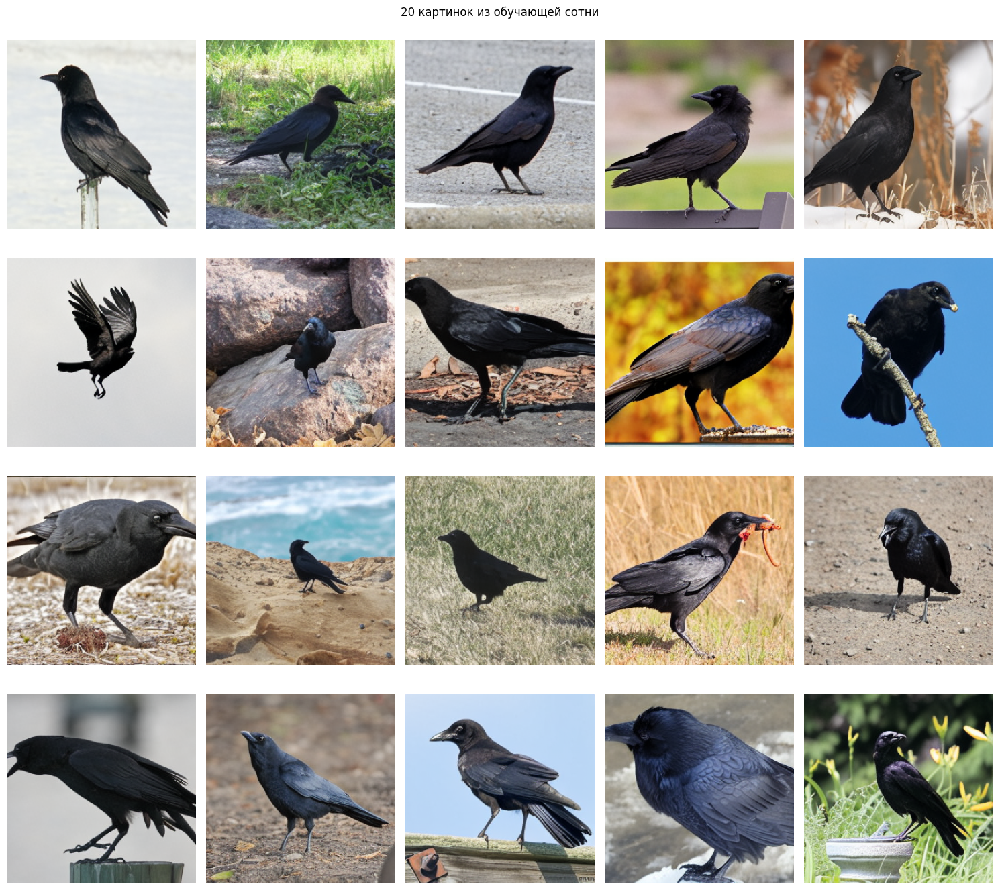

In [26]:
print(sorted(set(labels[:100])))
show_codes(data_img["codes"][80:100], suptitle="20 картинок из обучающей сотни")

[sanity_uncond] параметров: 7.85M, train: 100, val: 0
[sanity_uncond] загружен чекпоинт: train bpd 0.008


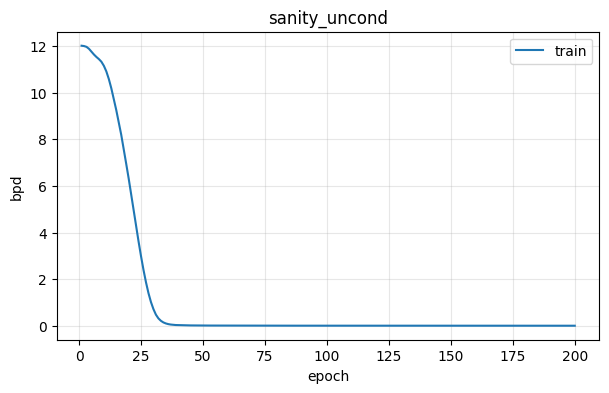

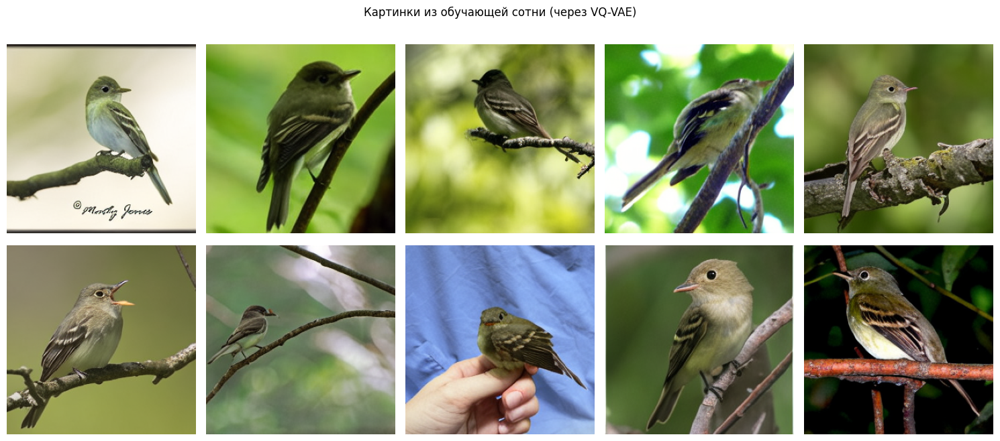

  0%|          | 0/32 [00:00<?, ?it/s]

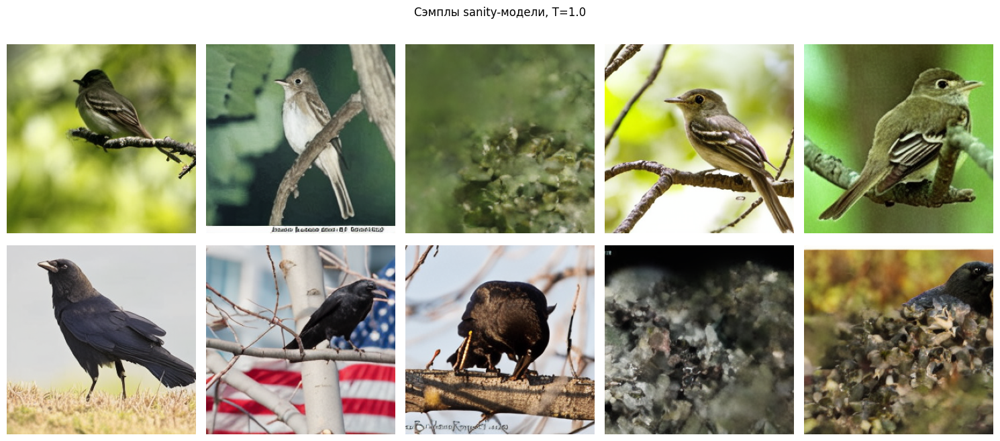

In [27]:
import time

sanity_uncond_cfg = TrainConfig(
    name="sanity_uncond", 
    epochs=200, 
    batch_size=20, 
    lr=1e-3,
    weight_decay=0.0, 
    warmup_steps=50, 
    log_every=20
)

BASE_MODEL = dict(hidden=128, n_layers=12, dilations=(1, 2, 4, 8))

sanity_uncond, hist_ = run_experiment(sanity_uncond_cfg, BASE_MODEL, sanity_idx)

show_codes(data_img["codes"][:10], suptitle="Картинки из обучающей сотни (через VQ-VAE)")
show_codes(
    sample(sanity_uncond, 10, temperature=1.0, seed=RAND_ST, show_progress=True),
    suptitle="Сэмплы sanity-модели, T=1.0"
)

### Обучение безусловной модели на всём датасете

[uncond_full] параметров: 7.85M, train: 11198, val: 589
[uncond_full] загружен чекпоинт: train bpd 9.779, val bpd 10.215


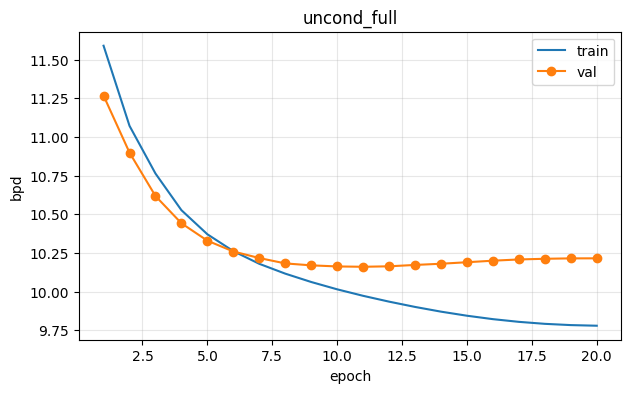

In [30]:
uncond_cfg = TrainConfig(
    name="uncond_full", 
    epochs=20, 
    batch_size=64, 
    lr=1e-3
)
uncond_model, uncond_hist = run_experiment(uncond_cfg, BASE_MODEL, train_idx, val_idx)

  0%|          | 0/32 [00:00<?, ?it/s]

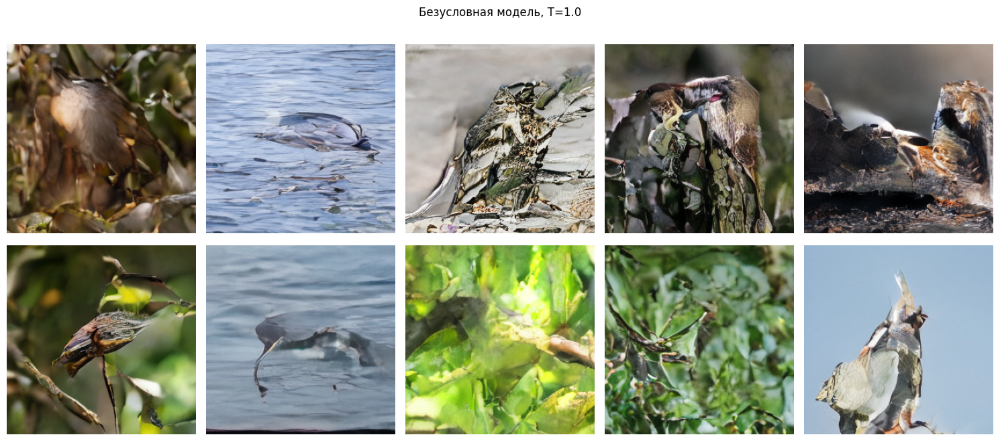

  0%|          | 0/32 [00:00<?, ?it/s]

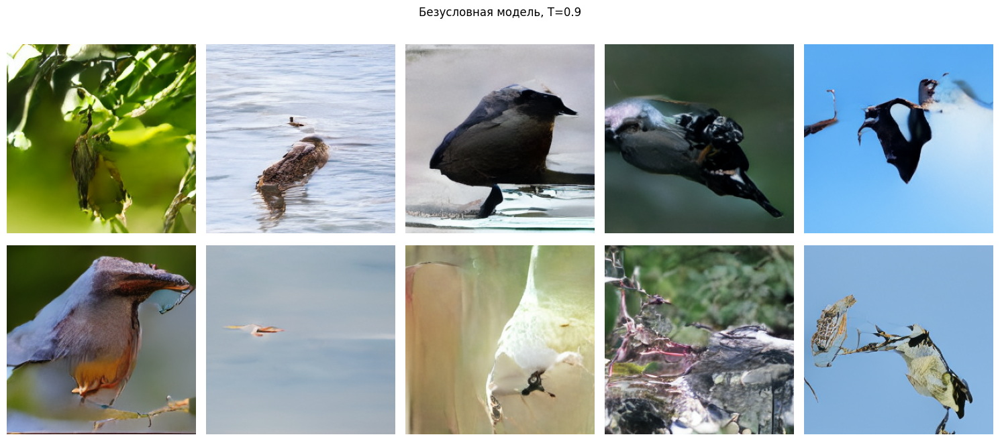

  0%|          | 0/32 [00:00<?, ?it/s]

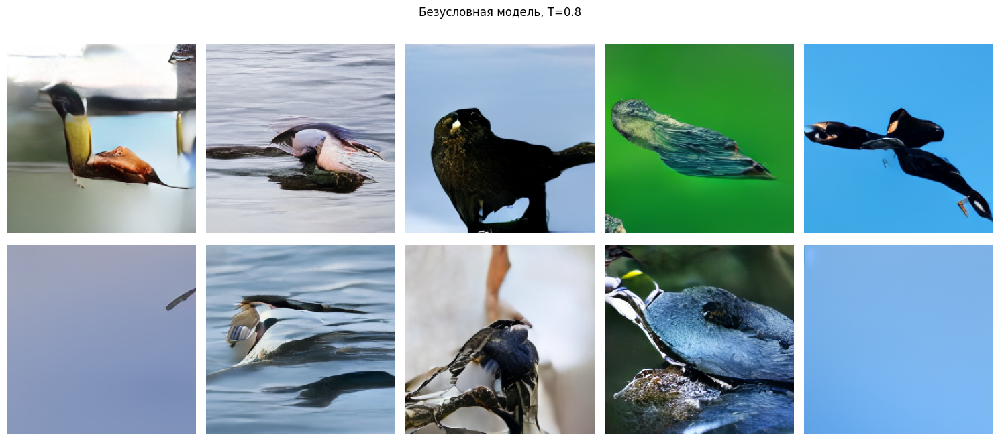

  0%|          | 0/32 [00:00<?, ?it/s]

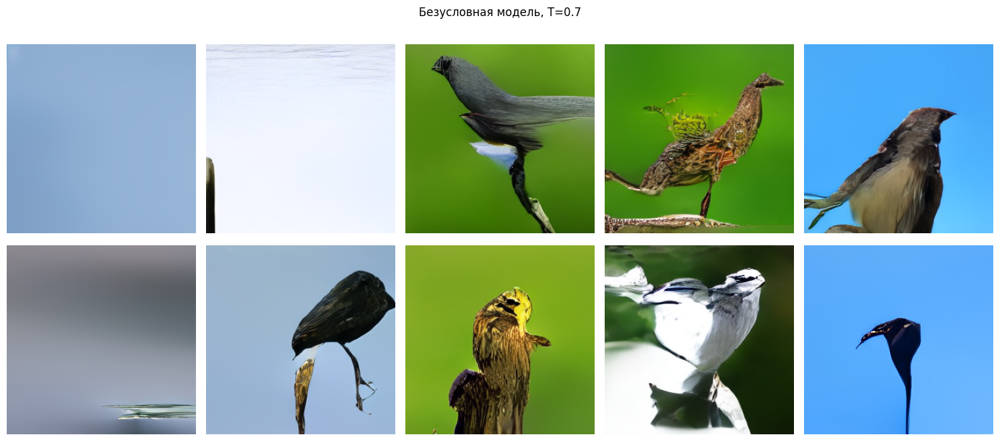

In [31]:
# 10 сэмплов при разных температурах (один и тот же seed, чтобы было честное сравнение)
for T in [1.0, 0.9, 0.8, 0.7]:
    gen = sample(uncond_model, 10, temperature=T, seed=RAND_ST+777, show_progress=True)
    show_codes(gen, suptitle=f"Безусловная модель, T={T}")

**Выводы:**

- Sanity check проходит: на 100 картинках  bpd на трэйне падает до **0.008**, и сэмплы почти копируют обучающие картинки двух классов птиц: `'Acadian Flycatcher'` и `'American Crow'`. Значит, маски, эмбединги кодов и функция потерь работают правильно, а утечки будущего нет;
- На всём датасете `bpd` на валидации быстро опускается примерно до **10.16**,но к концу 20-й эпохи чуть повышается до примерно **10.22** (для сравнения: случайная модель даёт 12 бит). Наблюдается переобучение (в модели нет дропаута и weight decay небольшой);
- При **T=1** картинки выглядят как пёстрая "мозаика" из фрагментов текстур. Скорее всего модель не уверенна и на каждой позиции иногда выбирает маловероятный код, а ошибки накапливаются. При **T от 0.8 до 0.9** больше появляются цельные фоны (зелень, небо, вода, ветки) и пятна, похожие на фигкры птицы. При более низкой температуре (**T=0.7**) некоторые картинки становятся однообразными и замыленными, но у некоторых даже хорошо различима фигура птицы. Модель выбирает самые частые коды, которые отражают фон;
- Модель хорошо учит локальную статистику и фоны, но глобальную форму птицы на 32x32 токенах передаёт плохо. Как я понял у PixelCNN ограниченное поле зрения и нет глобального представления о сцене.

### Задание 5 (3.5 балла).

- Добавьте сохраненные эмбеддинги подписей к архитектуре PixelCNN (это можно сделать любым способом - прибавить эмбеддинги, сконкатенировать их, использовать cross-attention или любой другой подход).

- Обучите такую conditional-модель на птицах и эмбеддингах текстов, выведите на экран по 10 промптам, похожим по формату на промпты из трейна, сгенерированные картинки. Оцените результат, напишите выводы (здесь вы тоже можете менять гиперпараметры модели)

**Hint:** для улучшения качества в последующих заданиях можете прочитать сначала условие задания 6

**Краткая вводная по реализации условного PixelCNN**

Эмбединг подписи (CLIP, 512) нормируется и проходит через MLP `Linear -> SiLU -> Linear` (`cond_net`). Затем в каждом гейтид слое отдельный линейный слой превращает его в сдвиги для пре-активаций вертикального и горизонтального стека (по каналам, одинаково во всех позициях). Так условие влияет на каждую позицию и на каждом слое. Авторегрессия здесь не нарушается, т.к условие известно заранее и не зависит от генерируемых кодов.

При обучении на каждом шаге берётся случайная подпись картинки (их примерно10, это работает и как аугментация текста). С вероятностью `p_uncond = 0.1` подпись заменяется эмбеддингом пустой строки. Таким образомм одна сеть учится быть и условной, и безусловной, что нужно для classifier-free guidance aka CFG (задание 6).

[sanity_cond] параметров: 8.72M, train: 100, val: 0
[sanity_cond] загружен чекпоинт: train bpd 0.007


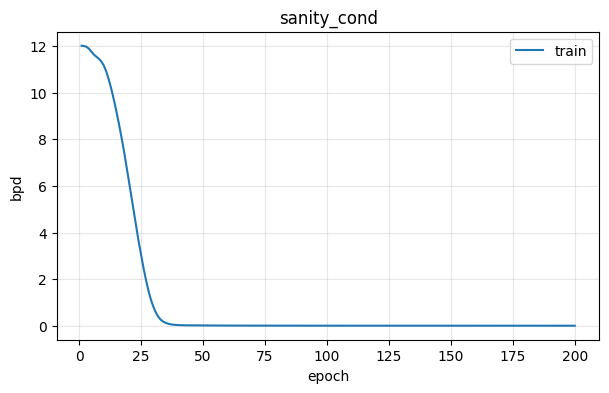

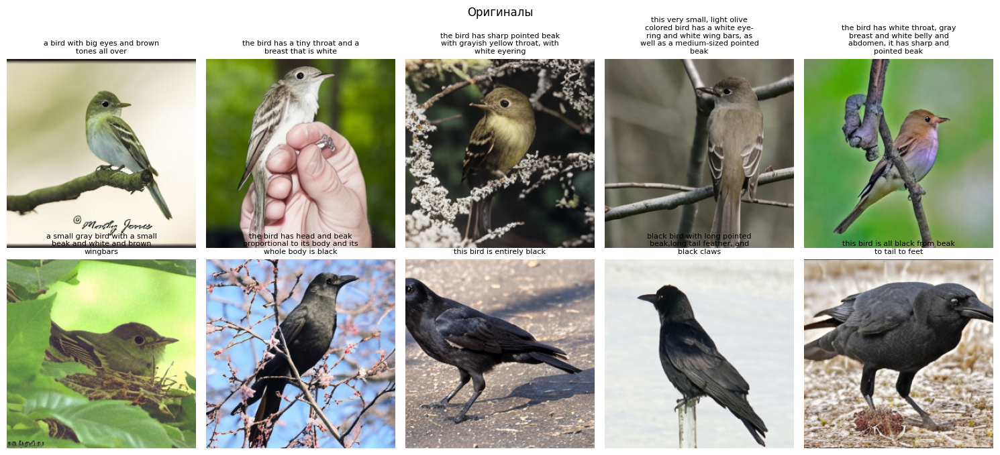

  0%|          | 0/32 [00:00<?, ?it/s]

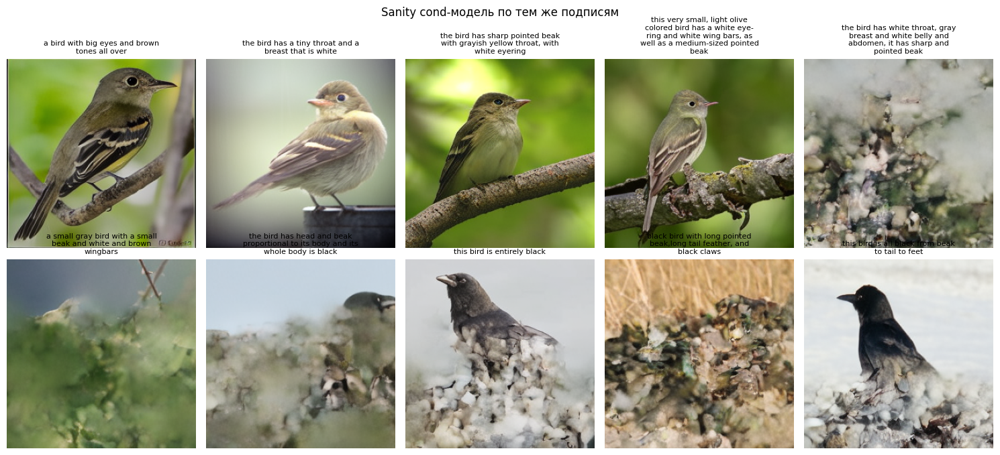

In [32]:
 # ваш код здесь
# sanity check для условной модели - 100 картинок + все их подписи
sanity_cond_cfg = TrainConfig(
    name="sanity_cond", 
    epochs=200, 
    batch_size=20, 
    lr=1e-3,
    weight_decay=0.0, 
    warmup_steps=50, 
    log_every=20, 
    p_uncond=0.1
)

sanity_cond, _ = run_experiment(sanity_cond_cfg, BASE_MODEL, sanity_idx, conditional=True)

# генерим по первым подписям 10 картинок из этой сотки и сравниваем с оригиналами
check_ids = list(range(0, 100, 10))
check_prompts = [captions[cap_ptr[i]] for i in check_ids]
check_emb = cap_emb[[int(cap_ptr[i]) for i in check_ids]]
show_codes(data_img["codes"][check_ids], check_prompts, suptitle="Оригиналы")
show_codes(sample(sanity_cond, 10, cond=check_emb, temperature=1.0, seed=0, show_progress=True),
           check_prompts, suptitle="Sanity cond-модель по тем же подписям")

[cond_full] параметров: 8.72M, train: 11198, val: 589
[cond_full] загружен чекпоинт: train bpd 9.789, val bpd 10.217


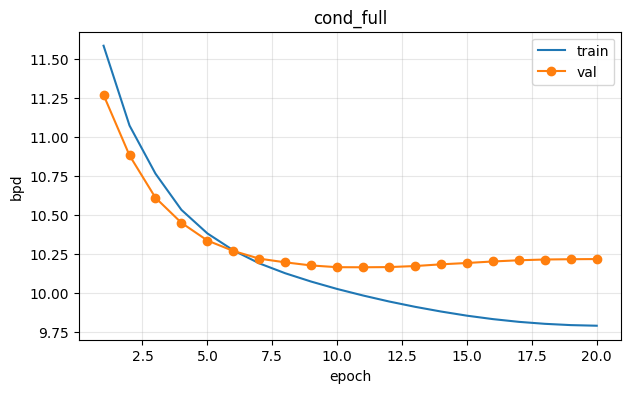

In [35]:
# обучение на всем трейн
cond_cfg = TrainConfig(
    name="cond_full", 
    epochs=20, 
    batch_size=64, 
    lr=1e-3, 
    p_uncond=0.1
)
cond_model, cond_hist = run_experiment(cond_cfg, BASE_MODEL, train_idx, val_idx, conditional=True)

  0%|          | 0/32 [00:00<?, ?it/s]

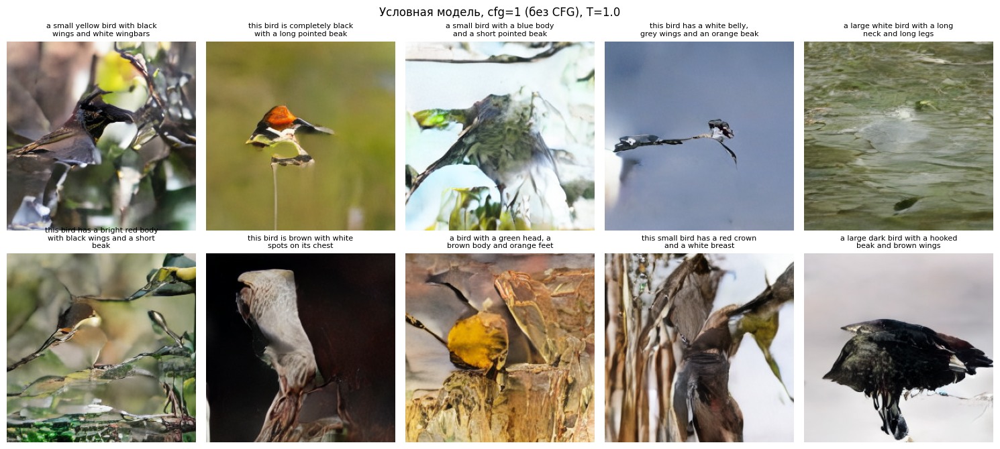

  0%|          | 0/32 [00:00<?, ?it/s]

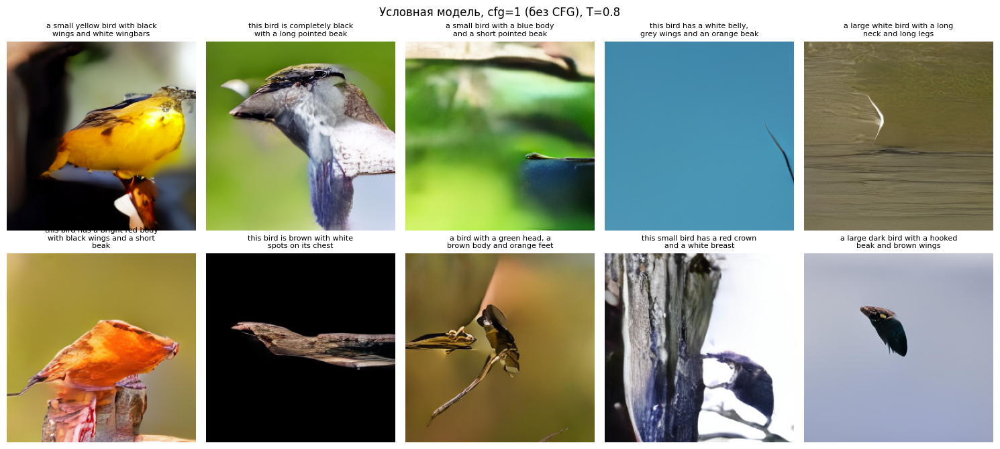

In [36]:
# сгенерированные подписи
prompts = [
    "a small yellow bird with black wings and white wingbars",
    "this bird is completely black with a long pointed beak",
    "a small bird with a blue body and a short pointed beak",
    "this bird has a white belly, grey wings and an orange beak",
    "a large white bird with a long neck and long legs",
    "this bird has a bright red body with black wings and a short beak",
    "this bird is brown with white spots on its chest",
    "a bird with a green head, a brown body and orange feet",
    "this small bird has a red crown and a white breast",
    "a large dark bird with a hooked beak and brown wings",
]
# получим по ним эмбединги + эмбединг пустой подписи
prompt_emb = encode_texts(prompts)
empty_emb = data_txt["empty_emb"]

# посмотрим на двух температурах
for T in [1.0, 0.8]:
    gen = sample(cond_model, len(prompts), cond=prompt_emb, temperature=T, seed=RAND_ST*3, show_progress=True)
    show_codes(gen, prompts, suptitle=f"Условная модель, cfg=1 (без CFG), T={T}")

**Выводы:**
- sanity check: на ста картинках условная модель переобучается и по подписи из обучающей сотни генерирует картинку, похожую на оригинал. Значит условие действительно доходит до модели и испольуется;
- На полном датасете bpd на валидации условной модели немного выше (на тысячные), чем у безусловной: за 20 эпох подпись почти не улучшает правдоподобие, цвет читается слабо;
- Промпт по идее должен влиять прежде всего на **цветовую состовляющую**: red - даёт красноватые пятна, yellow — жёлтые, white — светлые сцены. Детали (форма клюва, крылья) модель почти не воспроизводит: на это не хватает ёмкости и времени обучения. При этом для борьбы с переобучением необходимо добавить dropout, сделать немного больше weight decay как и в случае с безусловной моделью;
- Как и в безусловном случае, понижение температуры до 0.8 сильно улучшает картинки - фоны становятся цельными и чаще видны силуэты птиц. Как и написано в условии, температура влияет заметнее промпта;
- В целом в моем случае цвета в промпте (подписи) модель пока понимает плохо. При bpd на валидации около 10 температура меняет картинку сильнее, чем промпт.

### Задание 6 (0.5 балла).

Добавьте [classifier-free guidance](https://colab.research.google.com/drive/1EIsBxlTcz3ZB0j-ZxN1gWD2dSQq6krPj?usp=sharing) на этапе инференса для увеличения разнообразия генерации. Проведите несколько экспериментов.

Для улучшения качества и разнообразия генерации (опционально) можно добавить [classifier-free guidance и на этапе обучения](https://education.yandex.ru/handbook/ml/article/diffuzionnye-modeli):
- для этого во время обучения эмбеддинг промпта заменяется с какой-то фиксированной вероятностью (например, 10%) на эмбеддинг пустого промпта



this bird has a bright red bod:   0%|          | 0/5 [00:00<?, ?it/s]

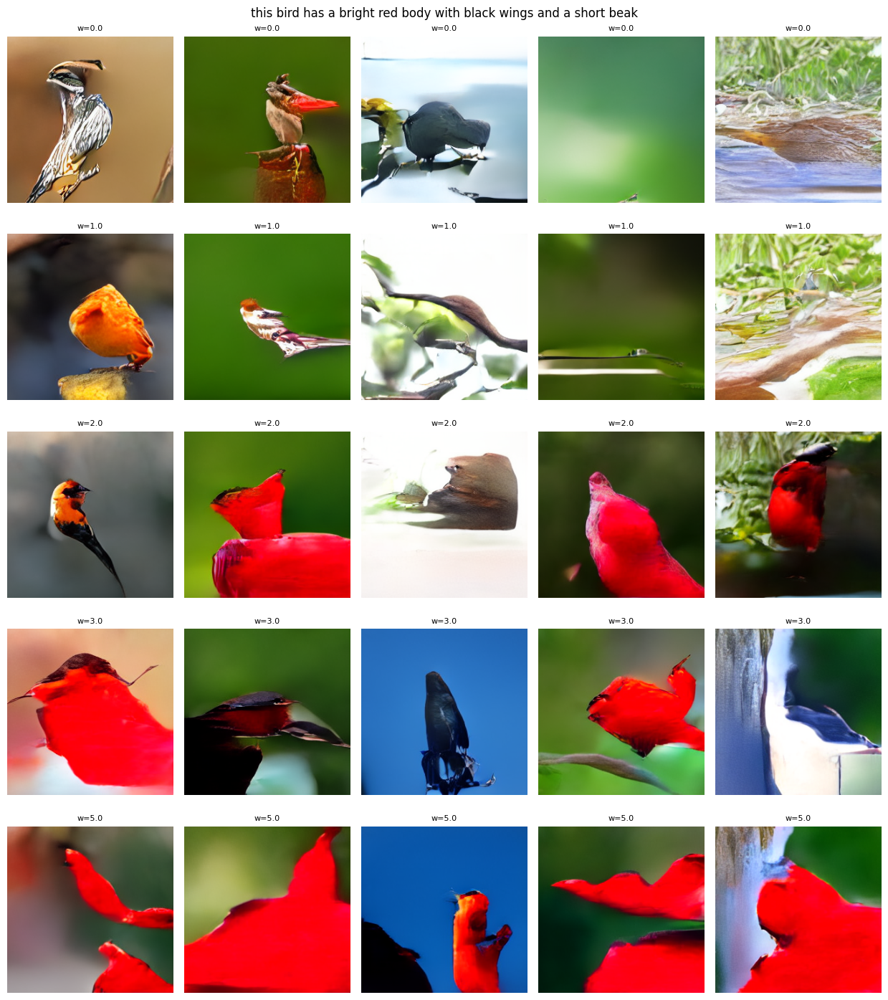

a small yellow bird with black:   0%|          | 0/5 [00:00<?, ?it/s]

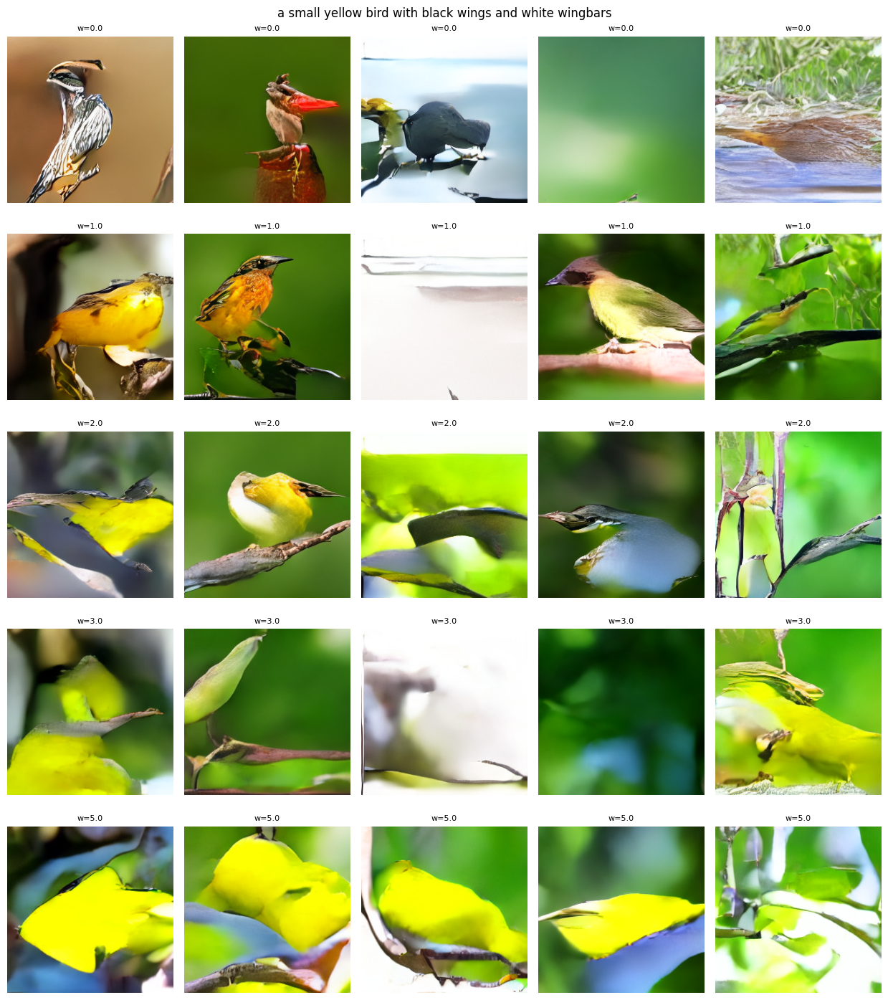

a large white bird with a long:   0%|          | 0/5 [00:00<?, ?it/s]

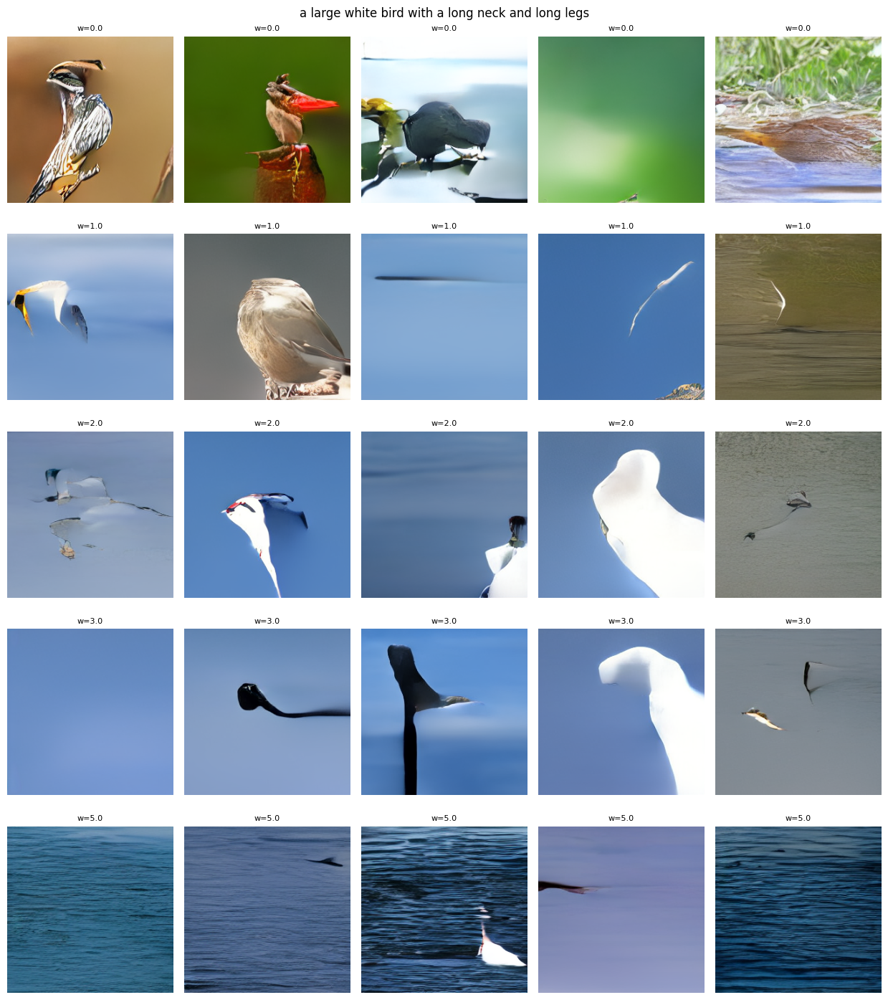

In [37]:
# ваш код здесь
cfg_prompts = [
    "this bird has a bright red body with black wings and a short beak",
    "a small yellow bird with black wings and white wingbars",
    "a large white bird with a long neck and long legs",
]
cfg_emb = encode_texts(cfg_prompts)
# попробуем с  разными весами cfg
cfg = [0.0, 1.0, 2.0, 3.0, 5.0]

for prompt, emb in zip(cfg_prompts, cfg_emb):
    gens = [sample(cond_model, 5, cond=emb, cfg=w, empty_emb=empty_emb, temperature=0.8, seed=RAND_ST*3)
            for w in tqdm(cfg, desc=prompt[:30])]
    titles = [f"w={w}" for w in cfg for _ in range(5)]
    show_codes(torch.cat(gens), titles, ncols=5, size=2.5, suptitle=prompt)

  0%|          | 0/32 [00:00<?, ?it/s]

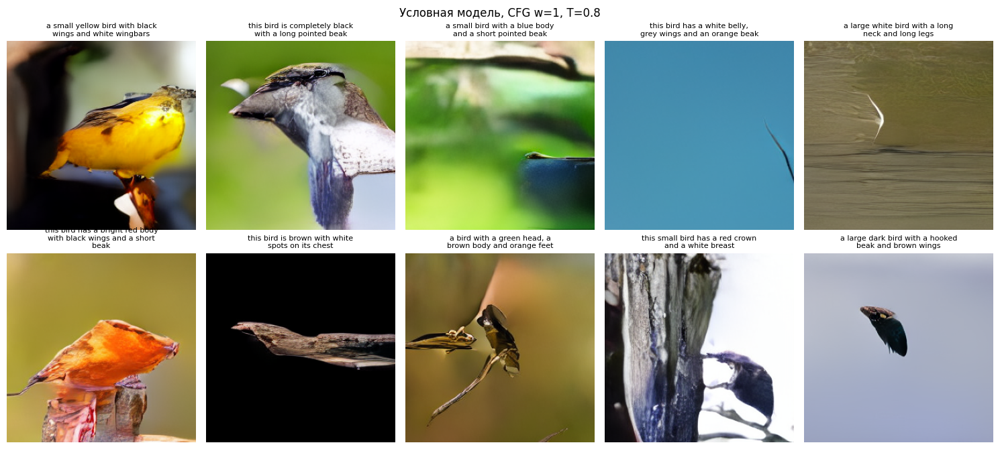

In [38]:
# теперь на тех же 10 промптах из задания 5 с cfg = 1.0 (по предыдущей генерации он показался мне более подходящим по результатам)
gen = sample(cond_model, len(prompts), cond=prompt_emb, cfg=1.0, empty_emb=empty_emb,
             temperature=0.8, seed=RAND_ST*3, show_progress=True)
show_codes(gen, prompts, suptitle="Условная модель, CFG w=1, T=0.8")

**Выводы:**
- При весе **w=0** - идет безусловная генерация и промпт игнорируется. При **w=1** влияние промпта есть, но умеренное. Мне кажется что в моем случае дает пока более лучший результат в условной генерации;
- При **w от 2 до 3** соответствие тексту заметно усиливается: цвет из промпта (красный, жёлтый, белый) проявляется почти в каждом сэмпле, контраст птица / фон становится сильнее, но теряется детальность самой птички;
- При больших **w = 5** картинки становятся пересыщенными и однообразными, появляются артефакты: распределение слишком сильно вытягивается в сторону промпта, и разнообразие падает;
- Разумный диапазон для моей модели - **w = [1,2]** вместе с **T=[0.8,0.9]**.

### Задание 7 (0.5 балла)

Реализуйте какую-нибудь метрику качества генерации - на ваш выбор (это может быть Inception Score, Frechet Inception Distance, LPIPS или что-то другое). Вам необходимо привести работающий код для вычисления метрики и текстом пояснить как работает метрика.

Далее вычислите значение этой метрики для обученной в задании 5 модели и сделайте выводы.

**Комментарий студента:**

Я всё-таки выберу **FID**, т.к. сравнивает сгенерированные картинки с реальными птицами из датасета. Обе выборки прогоняются через модель `Inception` и считается расстояние между их распредеениями. Чем меньше число, тем ближе генерация к данным и по виду и по разнообразию. Этим же числом потом удобно сравнивать модель из задания 5 и улучшенную модель из задания 8.

**Inception Score** для этого датасета будет хуже, т.к. не смотрит на ваших птиц, а только на то насколько `Inception` уверен в классах ImageNet. **LPIPS** меряет расстояние между парой картинок, а у сгенеренного сэмпла нет парного оригинала. **CLIP score** хорошо показывает соответствие подписи, но это уже как-будто не про качество картинки. Его имеет смысл добавить в задании 9, а в задании 7 оставить один **FID**.

**Выдержка ГПТ о метрике FID:**

**FID (Fréchet Inception Distance)** сравнивает распределения реальных и сгенерированных картинок в пространстве признаков сети Inception-v3 (обучена на ImageNet):
1. Каждая картинка прогоняется через Inception-v3, и берётся 2048-мерный вектор после global average pooling. Это «семантическое описание» картинки.
2. Для реальных и для сгенерированных картинок считаются среднее $\mu$ и ковариационная матрица $\Sigma$ этих векторов. Каждое множество приближается многомерным нормальным распределением.
3. Между двумя гауссианами считается расстояние Фреше (Вассерштейна-2):
$$\text{FID} = \|\mu_r - \mu_g\|^2 + \operatorname{Tr}\left(\Sigma_r + \Sigma_g - 2(\Sigma_r\Sigma_g)^{1/2}\right)$$
Первое слагаемое показывает, насколько сдвинуты «средние» картинки (качество / реалистичность), второе — насколько отличается разброс (разнообразие). Чем меньше FID, тем лучше; 0 — распределения совпадают.

**Важные моменты**: FID смещён и зависит от числа картинок (на 500 картинках он заметно выше, чем на 50 тыс.). Как будем считать:
- **FID** реальных картинок против других реальных. Это будет нижняя граница при наших 500 картинок.
- **FID** картинок, восстановленных VQ-VAE из настоящих кодов. Это будет потолок для любой модели, которая рисует только коды. Вобщем декодер лучше этого уже не сделает.

In [39]:
# ваш код здесь
from torchvision.models import inception_v3, Inception_V3_Weights
from scipy import linalg

# transform_input=False - своя нормализцаич
inception = inception_v3(
    weights=Inception_V3_Weights.IMAGENET1K_V1, 
    transform_input=False
).to(device).eval()

inception.fc = nn.Identity()  # весто 1000 классов берем вектор из 2048 признаков

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)


@torch.no_grad()
def inception_features(imgs):
    x = F.interpolate(
        imgs.to(device).float(), 
        size=(299, 299),            # nception-v3 ждёт картинки 299×299
        mode="bilinear",            # ресайзим билинейно
        align_corners=False
    )
    x = (x - IMAGENET_MEAN) / IMAGENET_STD
    
    return inception(x).double().cpu().numpy()


def fid_from_features(real_feats, gen_feats):

    # средние векторы и ковариационные матрицы 2048х2048 двух наборов признаков
    mu_r, mu_g = real_feats.mean(0), gen_feats.mean(0)
    sigma_r = np.cov(real_feats, rowvar=False)
    sigma_g = np.cov(gen_feats, rowvar=False)

    # матричный корень
    covmean = linalg.sqrtm(sigma_r @ sigma_g)    
    if isinstance(covmean, tuple):                # если возвращается tuple корректируем во избежание ошибок
        covmean = covmean[0]

    # если ковариации вырождены (например, картинок меньше, чем признаков)
    if not np.isfinite(covmean).all():
        # добавляем к диагонали маленькое число для устойчивости
        eps = 1e-6 * np.eye(sigma_r.shape[0])
        covmean = linalg.sqrtm((sigma_r + eps) @ (sigma_g + eps))
        
    covmean = np.real(covmean)
    # возвращаем результат по формуле FID
    return float(((mu_r - mu_g) ** 2).sum() + np.trace(sigma_r + sigma_g - 2 * covmean))


def features_from_codes(codes, batch_size=32):
    """Собираем батчами признаки из Inception предварительно прогоняя через декодер коды картинок"""
    parts = []
    for k in range(0, len(codes), batch_size):
        parts.append(inception_features(decode_codes(codes[k:k + batch_size])))        
    return np.concatenate(parts)


def features_from_images(indices, batch_size=32):
    """Собираем батчами признаки из Inception из нативных картинок"""
    loader = DataLoader(TensorImages(cub_data, indices), batch_size=batch_size)
    return np.concatenate([inception_features(batch) for batch in loader])

Референс это 2000 случайных реальных картинок из train. Генерировать будем 500 картинок по первым подписям 500 картинок из val (эти подписи модель не видела при обучении)

In [40]:
N_REF, N_GEN = 2000, 500
ref_idx = sorted(random.Random(RAND_ST).sample(train_idx, N_REF))
eval_idx = val_idx[:N_GEN]

# первая подпись каждой val-картинки
eval_text_emb = cap_emb[[int(cap_ptr[i]) for i in eval_idx]].float()

# для каждой группы получаем признаки из модели inception
ref_feats = features_from_images(ref_idx)
real_feats = features_from_images(eval_idx)
recon_feats = features_from_codes(data_img["codes"][eval_idx])

# сгенеренные коды кэшируются на диск, чтобы повторный запуск не ждал генерацию
gen_path = f"{SAVE_DIR}/gen_cond_fid.pt"
if os.path.exists(gen_path):
    gen_codes = torch.load(gen_path, weights_only=False)
else:
    gen_codes = sample_many(
        cond_model, 
        N_GEN, 
        cond=eval_text_emb,
        batch_size=100, 
        cfg=1.0, 
        temperature=1.0, 
        seed=RAND_ST,
    )
    torch.save(gen_codes, gen_path)
    
gen_feats = features_from_codes(gen_codes)

print(f"FID реальных картинок:{fid_from_features(ref_feats, real_feats):.2f}")
print(f"FID реконструкций VQ-VAE: {fid_from_features(ref_feats, recon_feats):.2f}")
print(f"FID условной модели: {fid_from_features(ref_feats, gen_feats):.2f}")

FID реальных картинок:20.70
FID реконструкций VQ-VAE: 23.01
FID условной модели: 121.52


In [41]:
# сгенеренные коды кэшируются на диск, чтобы повторный запуск не ждал генерацию
t = 0.8

gen_path = f"{SAVE_DIR}/gen_cond_fid_T_{t}.pt"
if os.path.exists(gen_path):
    gen_codes = torch.load(gen_path, weights_only=False)
else:
    gen_codes = sample_many(
        cond_model, 
        N_GEN, 
        cond=eval_text_emb,
        batch_size=100, 
        cfg=1.0, 
        temperature=t, 
        seed=RAND_ST,
    )
    torch.save(gen_codes, gen_path)
    
gen_feats = features_from_codes(gen_codes)

print("с температурой")
print(f"FID реальных картинок:{fid_from_features(ref_feats, real_feats):.2f}")
print(f"FID реконструкций VQ-VAE: {fid_from_features(ref_feats, recon_feats):.2f}")
print(f"FID условной модели: {fid_from_features(ref_feats, gen_feats):.2f}")

с температурой
FID реальных картинок:20.70
FID реконструкций VQ-VAE: 23.01
FID условной модели: 97.28


**Выводы:** 
- Реальные картинки дают минимальный FID при 500 картинках (**FID = 20.7**, он не нулевой из-за конечной выборки), реконструкции VQ-VAE - чуть чуть выше (**FID = 23.01**): это потолок качества для любой модели над этими кодами;
- **FID** нашей модели заметно выше обоих базовых уровней (**FID = 121.52**): модель пока генерирует в основном фоны и размытые силуэты;
- Понижение температуры снижает **FID = 97.28** : картинки становятся естественнее (гладкие фоны вместо пёстрого шума), что согласуется с визуальной оценкой.

### Задание 8 (0.5 балла).

Можете делать любые действия для улучшения работы вашей модели (менять число слоев, параметры архитектуры - не отходя от концепции PixelCNN, менять гиперпараметры, делать аугментацию изображений и текстов и так далее).

Проведите эксперименты по улучшению качества модели - оценивайте качество модели с точки зрения:
- Реализованной в задании 7 метрики
- Визуально.

Мы ожидаем, что качество может не вырасти, но и не упадет.

#### Мой эксперимент по улучшению

Что поменял относительно базовой условной модели (`hidden=128`, 12 слоёв, 20 эпох):
1. **Емкость**: `hidden=192`, 15 слоёв, dilations (1, 2, 1, 4, 8): больше слоёв с маленьким dilation дают более плотные локальные связи, а поле зрения по-прежнему покрывает всю карту 32×32.
2. **Аугментация картинок**: горизонтальное отражение с вероятностью 0.5 (коды отражённых картинок посчитаны заранее, в задании 3). Подписи птиц почти никогда не завист от лево/право, поэтому текст остается корректным.
3. **Регуляризация**: dropout 0.18 в gated-слоях и weight_decay = 5e-4 - модель больше и переобучение вероятнее.
4. **Дольше учим**: 40 эпох.

Аугментация текста (случайная подпись из примерно десяти на каждом шаге) уже есть и в базовой модели.

[cond_best_flip] параметров: 22.05M, train: 11198, val: 589
[cond_best_flip] загружен чекпоинт: train bpd 9.633, val bpd 9.903


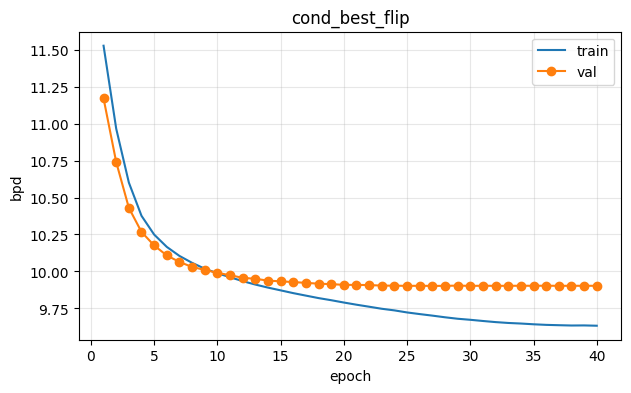

In [44]:
# ваш код здесь
BEST_MODEL = dict(
    hidden=192, 
    n_layers=15, 
    dilations=(1, 2, 1, 4, 8), 
    dropout=0.18
)
best_cfg = TrainConfig(
    name="cond_best_flip", 
    epochs=40, 
    batch_size=64,
    weight_decay=5e-4,
    lr=1e-3, 
    p_uncond=0.1, 
    flip_p=0.5
)

best_model, best_hist = run_experiment(best_cfg, BEST_MODEL, train_idx, val_idx, conditional=True)

sampling:   0%|          | 0/5 [00:00<?, ?it/s]

FID cond_full @ T=0.8:      97.28 | val bpd 10.217
FID cond_best_flip @ T=0.8: 67.42 | val bpd 9.903


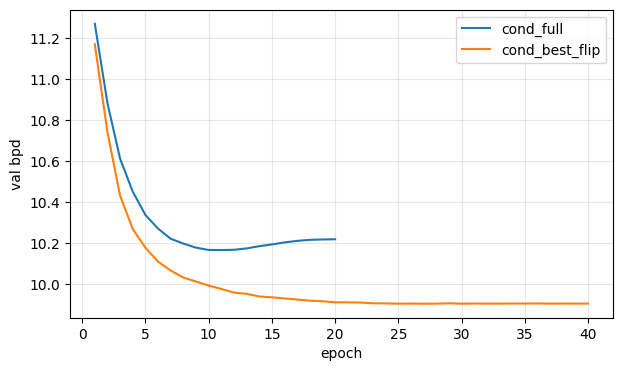

  0%|          | 0/32 [00:00<?, ?it/s]

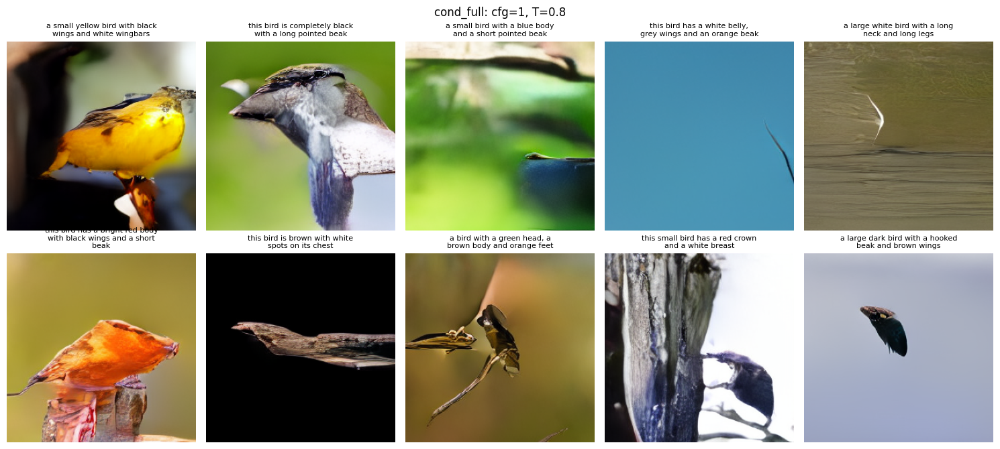

  0%|          | 0/32 [00:00<?, ?it/s]

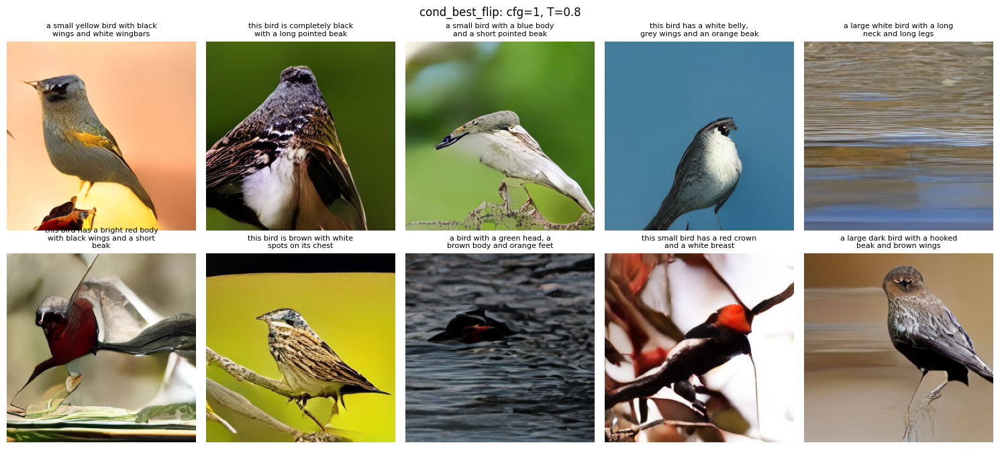

Лучшая по FID: cond_best_flip


In [51]:
t = 0.8
base_path = f"{SAVE_DIR}/gen_cond_fid_T_{t}.pt"
best_path = f"{SAVE_DIR}/gen_cond_best_fid_T_{t}.pt"

def load_or_sample(path, model, seed):
    if os.path.exists(path):
        return torch.load(path, weights_only=False)
    codes = sample_many(
        model,
        N_GEN,
        cond=eval_text_emb,
        batch_size=100,
        cfg=1.0,
        temperature=t,
        seed=seed,
    )
    torch.save(codes, path)
    return codes

base_codes = load_or_sample(base_path, cond_model, RAND_ST)
best_codes = load_or_sample(best_path, best_model, RAND_ST * 3)

fid_base = fid_from_features(ref_feats, features_from_codes(base_codes))
fid_best = fid_from_features(ref_feats, features_from_codes(best_codes))
print(f"FID cond_full @ T={t}:      {fid_base:.2f} | val bpd {cond_hist['val_bpd'][-1]:.3f}")
print(f"FID cond_best_flip @ T={t}: {fid_best:.2f} | val bpd {best_hist['val_bpd'][-1]:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(cond_hist["val_epoch"], cond_hist["val_bpd"], label="cond_full")
plt.plot(best_hist["val_epoch"], best_hist["val_bpd"], label="cond_best_flip")
plt.xlabel("epoch")
plt.ylabel("val bpd")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

for name, model in [("cond_full", cond_model), ("cond_best_flip", best_model)]:
    gen = sample(
        model, 
        len(prompts), 
        cond=prompt_emb, 
        cfg=1.0, 
        temperature=0.8,
        seed=RAND_ST*3, 
        show_progress=True
    )
    show_codes(gen, prompts, suptitle=f"{name}: cfg=1, T=0.8")

best_of_the_best_model = best_model if fid_best <= fid_base else cond_model
print("Лучшая по FID:", "cond_best_flip" if best_of_the_best_model is best_model else "cond_full")

**Выводы:**

- Увеличенная модель с аугментацией (отражением картинок по горизонтали) достигает более низкого bpd на валидации. Dropout, немного увеличенный weiht decay и flip сдерживают переобучение, поэтому разрыв train/val небольшой ;
- По **FID** при одинаковых настройках сэмплирования (одинаковый **w** и **T**) бОльшая модель не хуже базовой, и даже немного лучше (**FID = 67.42 против 97.28 у базовой модели при T=0.8**). Визуально фоны и цвета у неё немного лучше, а силуэты птиц встречаются как-будто бы чаще;
- В целом, думаю, что PixelCNN с локальными свёртками плохо моделирует глобальную структуру птиц, и дальнейший рост качества требует архитектурных изменений (attention, трансформер над кодами), выходящих уже за рамки PixelCNN.

### Задание 9 (1.5 балла).

Проанализируйте лучшую модель:

- Придумайте 5 разных признаков (например, цвет, вид оперения, длина клюва, лап и так далее) и посмотрите, будет ли модель их понимать благодаря текстовому эмбеддингу? (0.5 балла)

- Попробуйте добавлять в модель другие промпты - не связанные с птицами, или по-другому построенные (не "a photo of", а по-другому сформулированные). Как отрабатывает модель? (0.5 балла)

- Фиксируйте удачный промпт и проведите эксперименты по изменению веса guidance в classifer-free подходе. Сделайте выводы. (0.5 балла)

#### 9.1 5 Разных признаков

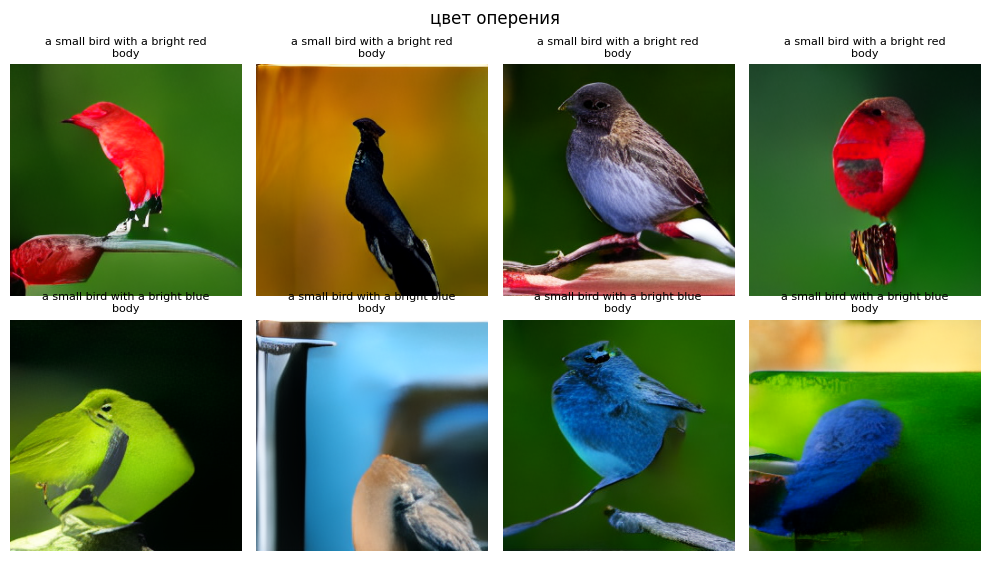

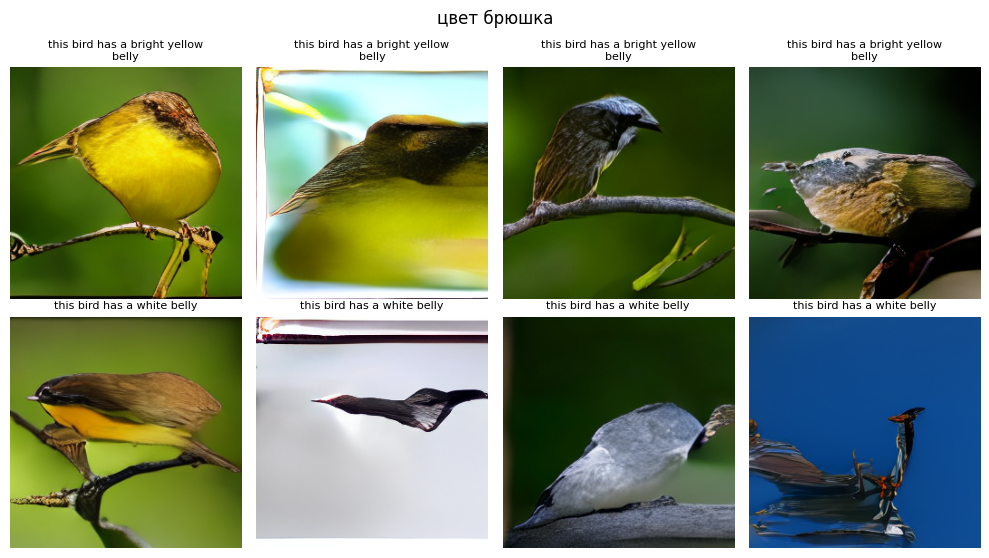

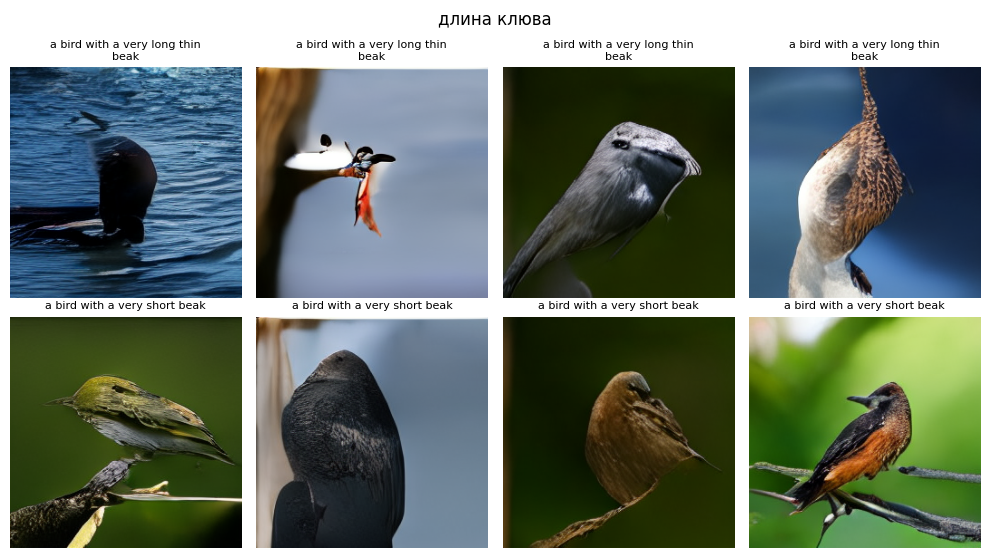

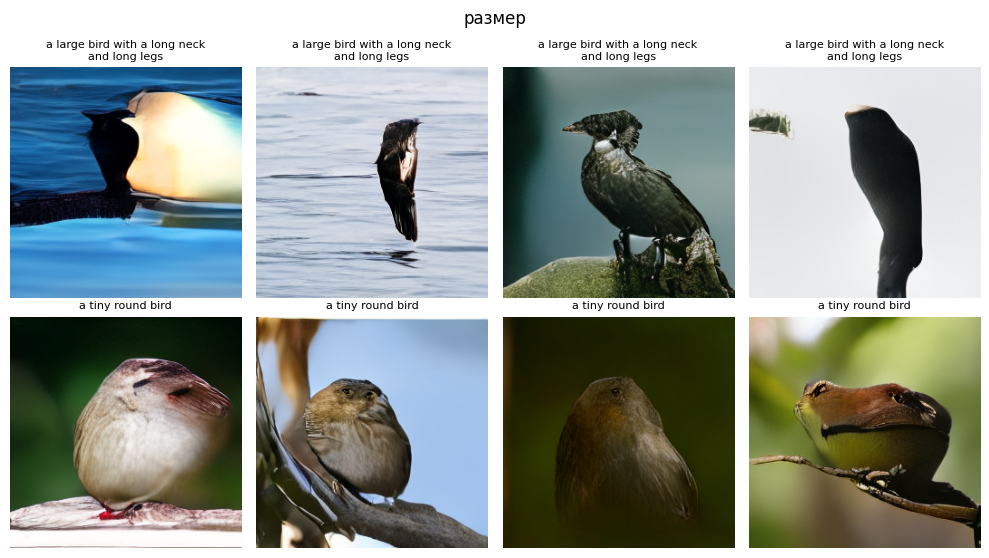

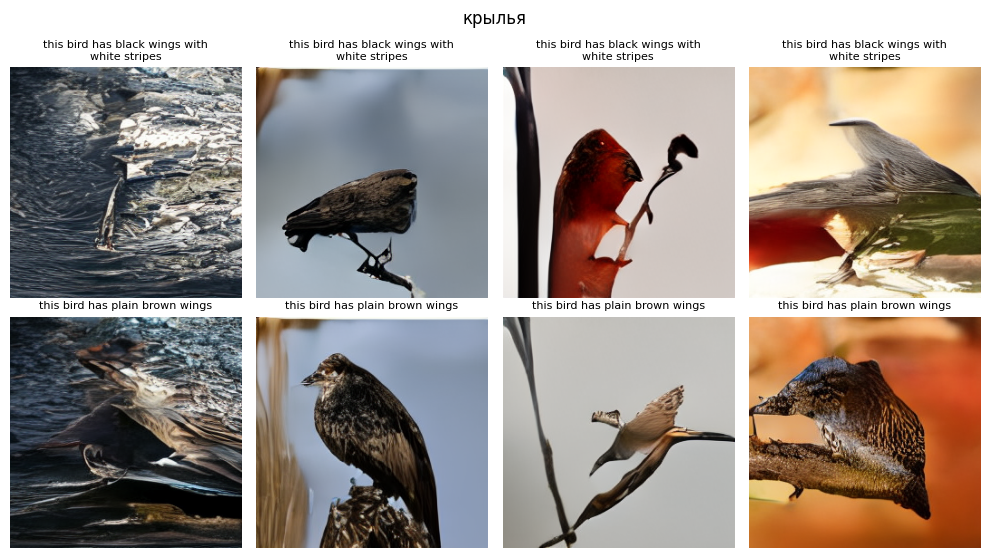

In [48]:
# ваш код здесь
# 5 признаков - пара противоположных промптов, одни и те же seed и cfg
attrs = {
    "цвет оперения": [
        "a small bird with a bright red body",
        "a small bird with a bright blue body",
    ],
    "цвет брюшка": [
        "this bird has a bright yellow belly",
        "this bird has a white belly",
    ],
    "длина клюва": [
        "a bird with a very long thin beak",
        "a bird with a very short beak",
    ],
    "размер": [
        "a large bird with a long neck and long legs",
        "a tiny round bird",
    ],
    "крылья": [
        "this bird has black wings with white stripes",
        "this bird has plain brown wings",
    ],
}

for name, pair in attrs.items():
    emb = encode_texts(pair)
    gens = [sample(best_model, 4, cond=e, cfg=1.0, temperature=0.8, seed=RAND_ST) for e in emb]
    titles = [p for p in pair for _ in range(4)]
    show_codes(torch.cat(gens), titles, ncols=4, size=2.5, suptitle=name)

**Выводы:**

- Цвет модель понимает лучше остальных признаков. При описании `bright red body` в двух сэмплах из четырёх птица явно красная; при `bright blue body` синий появляется тоже в 2-х картинках из четырех, остальные либо зелёный, либо черный или или коричневый. Жёлтое брюшко тоже часто проявляется на картинке, а белое - уже реже и путается с желтым; 
- Длина клюва, размер и рисунок крыльев почти не управляются текстом: и `long thin beak`, и `short beak` дают обычных птиц; 
- Размеры например `large bird with a long neck` не становится например цаплей, полоски на крыльях не читаются. 

При cfg=1 текст сдвигает в основном цвет, а не форму.

#### 9.2 Другие промпты

  0%|          | 0/32 [00:00<?, ?it/s]

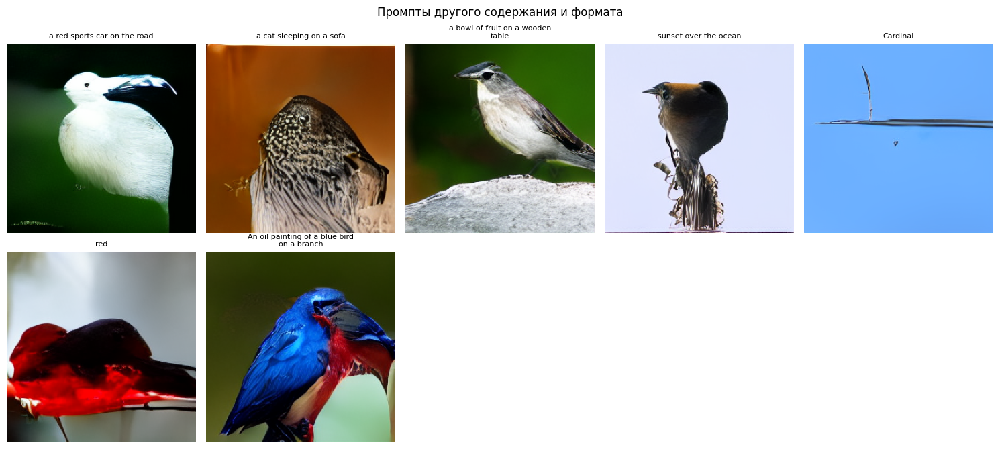

In [49]:
other_prompts = [
    "a red sports car on the road",
    "a cat sleeping on a sofa",
    "a bowl of fruit on a wooden table",
    "sunset over the ocean",
    "Cardinal",
    "red",
    "An oil painting of a blue bird on a branch",
]
other_emb = encode_texts(other_prompts)
gen = sample(
    best_model, 
    len(other_prompts), 
    cond=other_emb, 
    cfg=1.0, 
    temperature=0.8,
    seed=RAND_ST, 
    show_progress=True
)
show_codes(gen, other_prompts, suptitle="Промпты другого содержания и формата")

**Выводы:**

- Другие промпты (не про птиц) не позволяют модели покинуть распределение обучающей выборки (птиц). Машина, кот, фрукты и закат всё равно превращаются в птицу. 
- Одно слово `Cardinal` почти не задаёт контекста и содержания. Картинка пустая, с тонкой линией на синем. 
- Вот слова, похожие на обучающие подписи, срабатывают. Например слово `red` даёт красную фигуру отдаленно напоминающую птицу. `An oil painting of a blue bird on a branch` даёт синюю птицу с красным боюшком. Такое ощущение, что формат фразы сам по себе не важен, важно, есть ли в тексте цвет и слово bird.

#### 9.3 Фикс промпта и эксперименты по изменению веса guidance (cfg) в classifer-free подходе

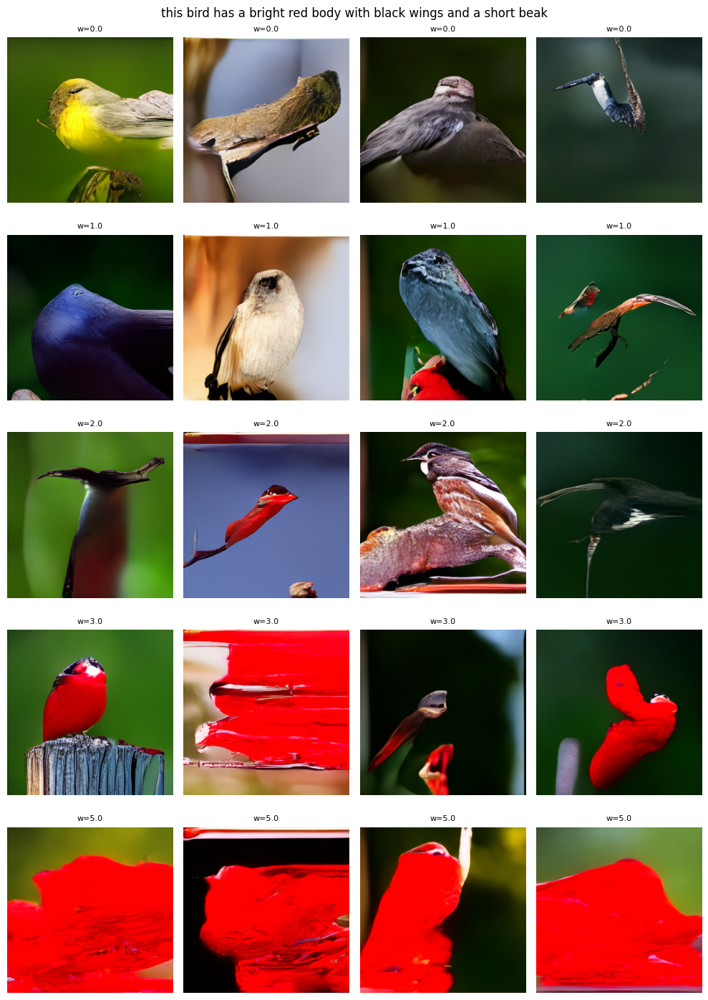

In [52]:
fixed_prompt = "this bird has a bright red body with black wings and a short beak"
fixed_emb = encode_texts([fixed_prompt])[0]
weights = [0.0, 1.0, 2.0, 3.0, 5.0]

gens = []
for w in weights:
    gens.append(sample(
        best_model, 
        4, 
        cond=fixed_emb, 
        cfg=w, 
        temperature=0.8,
        empty_emb=empty_emb, 
        seed=RAND_ST,
    ))
titles = [f"w={w}" for w in weights for _ in range(4)]
show_codes(torch.cat(gens), titles, ncols=4, size=2.5, suptitle=fixed_prompt)

**Выводы:**

Промпт фиксирован - красное тело, чёрные крылья, короткий клюв, **T=0.8**. 
- При **w=0** промпт не используется - на выходе генерации получаем жёлтые, бурые и серые птицы с незавершенной формой фигуры и деталей.
- При **w=1** красный почти не появляется. 
- При **w=2** красный возникает в одном сэмпле из четырёх. 
- При **w=3** красное тело видно уже в большинстве картинк, но часть сэмплов превращается в красные пятна. 
- При **w=5** птица пропадает, остаётся красная размазаннная текстура. 
- Чёрные крылья и короткий клюв практически не читаются ни при одном весе. 

Для этой модели разумный вес около 2-3 - цвет усиливается, а сцена ещё не разваливается полностью.